# ⚽ FIFA 23 Player Data Science Project

## Complete Data Science Workflow for Beginners

This notebook uses a FIFA 23 player dataset to teach the main stages of a data science project.

Students will learn how to:

1. define a practical problem;
2. import a CSV dataset;
3. understand rows, columns, variables, and data types;
4. inspect missing and duplicate data;
5. clean text, currency, units, and dates;
6. create useful new features;
7. explore the data using statistics and charts;
8. prepare data for machine learning;
9. train and evaluate a regression model;
10. communicate results and export cleaned data.

---

## Workflow

1. **Problem understanding**
2. **Data collection and import**
3. **Data understanding**
4. **Data-quality assessment**
5. **Data cleaning**
6. **Feature engineering**
7. **Exploratory data analysis**
8. **Model preparation**
9. **Model training**
10. **Model evaluation**
11. **Communication and export**

# 1. Problem Understanding

A data science project should begin with a clear question.

In this project, we analyse FIFA 23 player data to answer questions such as:

- What does a typical player look like?
- Who are the highest-rated players?
- Which young players have high potential?
- Which countries and clubs have the most listed players?
- How are age, potential, value, wage, and overall rating related?
- Can a simple model estimate a player's overall rating?

## Main goal

> Use FIFA 23 player data to demonstrate a complete data science workflow.

## Descriptive analysis

Descriptive analysis explains what is already present in the data.

Examples:

- average player age;
- most common nationality;
- top-rated players;
- distribution of ratings.

## Predictive analysis

Predictive analysis uses known variables to estimate an unknown value.

Later, we will build a simple model to predict:

```text
Overall player rating
```

The model is for teaching. It is not an official scouting or player-evaluation system.

# 2. Understanding the Dataset

The classroom file is:

```text
FIFA23_official_data.csv
```

It contains FIFA 23 video-game player information such as:

- player name;
- age;
- nationality;
- club;
- overall rating;
- potential;
- value and wage;
- preferred foot;
- skill moves;
- height and weight.

## Important clarification

This is **EA Sports FIFA 23 player-rating data**. It is not official match-performance data published by football's international governing body.

The notebook first looks for a local CSV file. In an internet-connected environment, it can use the public fallback address included in the import code.

# 3. Importing Python Libraries

A library is a collection of reusable Python tools.

We use:

- **Pandas** for CSV files and tables;
- **NumPy** for numerical operations;
- **Matplotlib** for charts;
- **Scikit-learn** for machine learning;
- **Pathlib** for file paths.

In [1]:
!pip install numpy pandas matplotlib ipython scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

NumPy version: 2.4.2
Pandas version: 3.0.0


### Beginner explanation: Importing the required libraries

**Purpose of this code:** This block loads the Python tools used throughout the notebook and checks the installed NumPy and Pandas versions.

#### Step-by-step explanation

1. `import warnings` loads Python’s warning-control module. A warning is different from an error: the program can usually continue, but Python wants to inform you about something.
2. `from pathlib import Path` imports only the `Path` class from the `pathlib` module. `Path` gives us a convenient way to represent file locations.
3. `import numpy as np` imports NumPy and gives it the short name `np`. NumPy is mainly used for numerical calculations and arrays.
4. `import pandas as pd` imports Pandas as `pd`. Pandas provides the `DataFrame` structure used to store and analyse table-shaped data.
5. `import matplotlib.pyplot as plt` imports Matplotlib’s plotting functions as `plt`. Later, calls such as `plt.xlabel()` and `plt.show()` use this short name.
6. `from IPython.display import display` imports the `display()` function, which presents DataFrames neatly inside Jupyter or Google Colab.
7. The six `from sklearn...` lines import specific machine-learning tools: missing-value imputation, linear regression, evaluation metrics, train-test splitting, pipelines, and feature scaling.
8. `warnings.filterwarnings("ignore")` asks Python to hide warning messages. It does not hide actual errors.
9. `print("NumPy version:", np.__version__)` prints some text followed by NumPy’s version number. The same pattern is used for Pandas.

#### Syntax explained

- `import package` loads an entire package, while `from package import item` loads a specific item.
- `as np`, `as pd`, and `as plt` create short aliases. These aliases are conventional names used by most Python data scientists.
- A dot, as in `np.__version__`, means “access an attribute belonging to this object or module.”
- Parentheses `()` are used to call a function. Text inside quotation marks is a Python string.
- Commas separate multiple arguments passed to a function.


# 4. Data Collection and CSV Import

`pd.read_csv()` imports a CSV file and returns a Pandas DataFrame.

A DataFrame is similar to an Excel worksheet:

- each row represents one player;
- each column represents one characteristic.

The code below:

1. checks whether the CSV is in the notebook folder;
2. loads it if available;
3. otherwise attempts to read a public online copy;
4. stores the imported table in `raw_df`.

In [4]:
LOCAL_FILE = Path(r"C:\Data Science\Updated\FIFA23_Data_Science_Files\FIFA23_DS\FIFA23_official_data.csv")

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "guebin/DV2022/master/posts/FIFA23_official_data.csv"
)

if LOCAL_FILE.exists():
    raw_df = pd.read_csv(LOCAL_FILE)
    print(f"Loaded local file: {LOCAL_FILE}")
else:
    raw_df = pd.read_csv(DATA_URL)
    raw_df.to_csv(LOCAL_FILE, index=False)
    print("Downloaded the dataset and saved a local copy.")

print("Dataset imported successfully.")

Loaded local file: C:\Data Science\Updated\FIFA23_Data_Science_Files\FIFA23_DS\FIFA23_official_data.csv
Dataset imported successfully.


### Explanation: Loading the FIFA CSV file

**Purpose of this code:** This block first looks for a local CSV file. If it exists, Pandas reads it; otherwise, the file is downloaded from the given web address and saved locally.

#### Step-by-step explanation

1. `LOCAL_FILE = Path("FIFA23_official_data.csv")` creates a `Path` object and stores it in the variable `LOCAL_FILE`. The uppercase name signals that this value is intended to remain constant.
2. `DATA_URL = (...)` stores the dataset’s internet address. Python automatically joins adjacent string literals inside parentheses, so the two URL pieces become one complete string.
3. `if LOCAL_FILE.exists():` asks a yes-or-no question: does the file exist? The colon starts the indented block that runs when the answer is `True`.
4. `raw_df = pd.read_csv(LOCAL_FILE)` reads the CSV into a Pandas DataFrame called `raw_df`. “raw” reminds us that the data has not yet been cleaned.
5. `print(f"Loaded local file: {LOCAL_FILE}")` uses an f-string. Anything inside `{}` is replaced by its current value.
6. `else:` gives the alternative instructions that run when the local file is missing.
7. `pd.read_csv(DATA_URL)` reads the CSV directly from the web address.
8. `raw_df.to_csv(LOCAL_FILE, index=False)` saves the downloaded data. `index=False` prevents Pandas from adding the DataFrame row numbers as an extra CSV column.
9. The final `print()` confirms that one of the two loading paths completed successfully.

#### Syntax explained

- `=` is the assignment operator: it stores the value on the right in the variable on the left.
- An `if ... else ...` structure selects one of two possible paths.
- Indentation is part of Python syntax. The indented lines belong to the preceding `if` or `else` block.
- A method such as `.exists()` or `.to_csv()` is a function attached to an object.
- Keyword arguments use the form `name=value`, such as `index=False`.


## 4.1 Keep the Raw Data Unchanged

We create a working copy called `df`.

- `raw_df` remains unchanged;
- `df` will be cleaned and analysed.

This is important because we can always return to the original imported data.

In [5]:
df = raw_df.copy()

print("Raw shape:", raw_df.shape)
print("Working-copy shape:", df.shape)

df.head()

Raw shape: (17660, 29)
Working-copy shape: (17660, 29)


,ID,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,Club Logo,...,Real Face,Position,Joined,Loaned From,Contract Valid Until,Height,Weight,Release Clause,Kit Number,Best Overall Rating
0,209658,L. Goretzka,27,https://cdn.sofifa.net/players/209/658/23_60.png,Germany,https://cdn.sofifa.net/flags/de.png,87,88,FC Bayern München,https://cdn.sofifa.net/teams/21/30.png,...,Yes,"<span class=""pos pos28"">SUB","Jul 1, 2018",NaN,2026,189cm,82kg,€157M,8.0,NaN
1,212198,Bruno Fernandes,27,https://cdn.sofifa.net/players/212/198/23_60.png,Portugal,https://cdn.sofifa.net/flags/pt.png,86,87,Manchester United,https://cdn.sofifa.net/teams/11/30.png,...,Yes,"<span class=""pos pos15"">LCM","Jan 30, 2020",NaN,2026,179cm,69kg,€155M,8.0,NaN
2,224334,M. Acuña,30,https://cdn.sofifa.net/players/224/334/23_60.png,Argentina,https://cdn.sofifa.net/flags/ar.png,85,85,Sevilla FC,https://cdn.sofifa.net/teams/481/30.png,...,No,"<span class=""pos pos7"">LB","Sep 14, 2020",NaN,2024,172cm,69kg,€97.7M,19.0,NaN
3,192985,K. De Bruyne,31,https://cdn.sofifa.net/players/192/985/23_60.png,Belgium,https://cdn.sofifa.net/flags/be.png,91,91,Manchester City,https://cdn.sofifa.net/teams/10/30.png,...,Yes,"<span class=""pos pos13"">RCM","Aug 30, 2015",NaN,2025,181cm,70kg,€198.9M,17.0,NaN
4,224232,N. Barella,25,https://cdn.sofifa.net/players/224/232/23_60.png,Italy,https://cdn.sofifa.net/flags/it.png,86,89,Inter,https://cdn.sofifa.net/teams/44/30.png,...,Yes,"<span class=""pos pos13"">RCM","Sep 1, 2020",NaN,2026,172cm,68kg,€154.4M,23.0,NaN


### Explanation: Creating a safe working copy

**Purpose of this code:** This block copies the original DataFrame so that later cleaning operations do not directly change `raw_df`.

#### Step-by-step explanation

1. `df = raw_df.copy()` makes an independent copy of the original DataFrame and stores it as `df`.
2. `raw_df.shape` returns a pair containing the number of rows and columns in the raw data.
3. `df.shape` checks the dimensions of the copied DataFrame. At this point, both shapes should match.
4. `df.head()` returns the first five rows. In a notebook, the value from the final line is displayed automatically even without `print()`.

#### Syntax explained

- A variable name such as `df` is a label that refers to an object in memory.
- `.copy()` is important because `df = raw_df` alone could make both names refer to the same underlying object.
- `.shape` is an attribute, so it does not use parentheses.
- `.head()` is a method, so it uses parentheses.


# 5. Data Understanding

Before cleaning or modelling, we need to understand the dataset.

We should check:

- number of rows and columns;
- first, last, and random rows;
- column names;
- data types;
- numerical summaries.

In [6]:
rows, columns = df.shape

print("Number of players:", rows)
print("Number of columns:", columns)

print("\nColumn names:")
print(df.columns.tolist())

Number of players: 17660
Number of columns: 29

Column names:
['ID', 'Name', 'Age', 'Photo', 'Nationality', 'Flag', 'Overall', 'Potential', 'Club', 'Club Logo', 'Value', 'Wage', 'Special', 'Preferred Foot', 'International Reputation', 'Weak Foot', 'Skill Moves', 'Work Rate', 'Body Type', 'Real Face', 'Position', 'Joined', 'Loaned From', 'Contract Valid Until', 'Height', 'Weight', 'Release Clause', 'Kit Number', 'Best Overall Rating']


### Explanation: Reading the dataset dimensions and column names

**Purpose of this code:** This block separates the DataFrame shape into row and column counts and prints every column name.

#### Step-by-step explanation

1. `rows, columns = df.shape` uses unpacking. The first number from the shape tuple goes into `rows`, and the second goes into `columns`.
2. The next two `print()` calls display labelled row and column counts.
3. `"\nColumn names:"` begins with `\n`, a newline escape sequence that inserts a blank line before the heading.
4. `df.columns` returns the column index, and `.tolist()` converts it to an ordinary Python list before printing.

#### Syntax explained

- Tuple unpacking allows several variables to receive several values in one statement.
- `\n` means “start a new line” inside a string.
- Square brackets `[]` usually represent a list or select data; here `.tolist()` creates a list.
- Method chaining, such as `df.columns.tolist()`, applies one operation after another.


In [7]:
print("First five rows:")
display(df.head())

print("Last three rows:")
display(df.tail(3))

print("Three random rows:")
display(df.sample(3, random_state=42))

First five rows:


,ID,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,Club Logo,...,Real Face,Position,Joined,Loaned From,Contract Valid Until,Height,Weight,Release Clause,Kit Number,Best Overall Rating
0,209658,L. Goretzka,27,https://cdn.sofifa.net/players/209/658/23_60.png,Germany,https://cdn.sofifa.net/flags/de.png,87,88,FC Bayern München,https://cdn.sofifa.net/teams/21/30.png,...,Yes,"<span class=""pos pos28"">SUB","Jul 1, 2018",NaN,2026,189cm,82kg,€157M,8.0,NaN
1,212198,Bruno Fernandes,27,https://cdn.sofifa.net/players/212/198/23_60.png,Portugal,https://cdn.sofifa.net/flags/pt.png,86,87,Manchester United,https://cdn.sofifa.net/teams/11/30.png,...,Yes,"<span class=""pos pos15"">LCM","Jan 30, 2020",NaN,2026,179cm,69kg,€155M,8.0,NaN
2,224334,M. Acuña,30,https://cdn.sofifa.net/players/224/334/23_60.png,Argentina,https://cdn.sofifa.net/flags/ar.png,85,85,Sevilla FC,https://cdn.sofifa.net/teams/481/30.png,...,No,"<span class=""pos pos7"">LB","Sep 14, 2020",NaN,2024,172cm,69kg,€97.7M,19.0,NaN
3,192985,K. De Bruyne,31,https://cdn.sofifa.net/players/192/985/23_60.png,Belgium,https://cdn.sofifa.net/flags/be.png,91,91,Manchester City,https://cdn.sofifa.net/teams/10/30.png,...,Yes,"<span class=""pos pos13"">RCM","Aug 30, 2015",NaN,2025,181cm,70kg,€198.9M,17.0,NaN
4,224232,N. Barella,25,https://cdn.sofifa.net/players/224/232/23_60.png,Italy,https://cdn.sofifa.net/flags/it.png,86,89,Inter,https://cdn.sofifa.net/teams/44/30.png,...,Yes,"<span class=""pos pos13"">RCM","Sep 1, 2020",NaN,2026,172cm,68kg,€154.4M,23.0,NaN


Last three rows:


,ID,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,Club Logo,...,Real Face,Position,Joined,Loaned From,Contract Valid Until,Height,Weight,Release Clause,Kit Number,Best Overall Rating
17657,270567,A. Demir,25,https://cdn.sofifa.net/players/270/567/23_60.png,Turkey,https://cdn.sofifa.net/flags/tr.png,51,56,Ümraniyespor,https://cdn.sofifa.net/teams/113796/30.png,...,No,"<span class=""pos pos29"">RES","Jun 6, 2021",NaN,2023,190cm,82kg,€142K,12.0,NaN
17658,256624,21 S. Czajor,18,https://cdn.sofifa.net/players/256/624/21_60.png,Poland,https://cdn.sofifa.net/flags/pl.png,50,65,Fleetwood Town,https://cdn.sofifa.net/teams/112260/30.png,...,No,"<span class=""pos pos29"">RES","Jan 1, 2020",NaN,2021,187cm,79kg,€214K,40.0,NaN
17659,256376,21 F. Jakobsson,20,https://cdn.sofifa.net/players/256/376/21_60.png,Sweden,https://cdn.sofifa.net/flags/se.png,50,61,IFK Norrköping,https://cdn.sofifa.net/teams/702/30.png,...,No,"<span class=""pos pos29"">RES","Jan 8, 2020",NaN,2021,186cm,78kg,€131K,30.0,NaN


Three random rows:


,ID,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,Club Logo,...,Real Face,Position,Joined,Loaned From,Contract Valid Until,Height,Weight,Release Clause,Kit Number,Best Overall Rating
9920,259986,22 C. Van Daele,20,https://cdn.sofifa.net/players/259/986/22_60.png,Belgium,https://cdn.sofifa.net/flags/be.png,58,67,KAA Gent,https://cdn.sofifa.net/teams/674/30.png,...,No,"<span class=""pos pos29"">RES","Nov 1, 2020",NaN,2023,177cm,63kg,€723K,35.0,NaN
8171,259341,22 I. Violante,17,https://cdn.sofifa.net/players/259/341/22_60.png,Mexico,https://cdn.sofifa.net/flags/mx.png,61,72,Deportivo Toluca,https://cdn.sofifa.net/teams/1882/30.png,...,No,"<span class=""pos pos28"">SUB","Mar 21, 2022",NaN,2025,173cm,69kg,€1.2M,90.0,NaN
16308,241978,21 C. Higuera,19,https://cdn.sofifa.net/players/241/978/21_60.png,Mexico,https://cdn.sofifa.net/flags/mx.png,63,78,Club Tijuana,https://cdn.sofifa.net/teams/111678/30.png,...,No,"<span class=""pos pos28"">SUB","Jan 1, 2019",NaN,2023,182cm,77kg,€2.3M,29.0,NaN


### Explanation: Viewing rows from different parts of the dataset

**Purpose of this code:** This code displays the beginning, end, and a reproducible random sample of the DataFrame.

#### Step-by-step explanation

1. `display(df.head())` shows the first five rows in a formatted table.
2. `display(df.tail(3))` shows the last three rows. The number `3` is an argument telling `tail()` how many rows to return.
3. `display(df.sample(3, random_state=42))` selects three random rows.
4. `random_state=42` fixes the random starting state. This makes the same three rows appear each time the notebook is run, which supports reproducibility.

#### Syntax explained

- A positional argument is identified by its position, such as `3` in `tail(3)`.
- A keyword argument is named explicitly, such as `random_state=42`.
- Nested function calls are evaluated from the inside outward: first `df.head()`, then `display(...)`.


## 5.1 Data Types

Common Pandas data types include:

- `int64`: whole numbers;
- `float64`: decimal numbers;
- `object`: text or mixed content;
- `bool`: True or False;
- `datetime64`: dates and times.

Some columns look numerical but are stored as text because they contain units or symbols.

Examples:

```text
€91M
€115K
189cm
82kg
```

In [8]:
df.dtypes

ID                            int64
Name                            str
Age                           int64
Photo                           str
Nationality                     str
Flag                            str
Overall                       int64
Potential                     int64
Club                            str
Club Logo                       str
Value                           str
Wage                            str
Special                       int64
Preferred Foot                  str
International Reputation    float64
Weak Foot                   float64
Skill Moves                 float64
Work Rate                       str
Body Type                       str
Real Face                       str
Position                        str
Joined                          str
Loaned From                     str
Contract Valid Until            str
Height                          str
Weight                          str
Release Clause                  str
Kit Number                  

### Explanation: Checking column data types

**Purpose of this code:** This one-line block reports the data type stored in every DataFrame column.

#### Step-by-step explanation

1. `df.dtypes` returns a Pandas Series whose index contains the column names and whose values contain data types such as `int64`, `float64`, `object`, or `bool`.
2. This check helps us identify columns that need conversion. For example, currency stored as text cannot be used directly in numerical calculations.

#### Syntax explained

- No parentheses are used because `dtypes` is an attribute, not a method.
- A one-line expression at the end of a notebook cell is displayed automatically.


## 5.2 `info()` and `describe()`

`info()` shows:

- column names;
- non-missing counts;
- data types;
- memory information.

`describe()` gives numerical statistics such as:

- count;
- mean;
- standard deviation;
- minimum;
- quartiles;
- maximum.

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17660 entries, 0 to 17659
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        17660 non-null  int64  
 1   Name                      17660 non-null  str    
 2   Age                       17660 non-null  int64  
 3   Photo                     17660 non-null  str    
 4   Nationality               17660 non-null  str    
 5   Flag                      17660 non-null  str    
 6   Overall                   17660 non-null  int64  
 7   Potential                 17660 non-null  int64  
 8   Club                      17449 non-null  str    
 9   Club Logo                 17660 non-null  str    
 10  Value                     17660 non-null  str    
 11  Wage                      17660 non-null  str    
 12  Special                   17660 non-null  int64  
 13  Preferred Foot            17660 non-null  str    
 14  International Rep

### Explanation: Getting a structural summary with `info()`

**Purpose of this code:** This code prints a compact overview of the DataFrame, including row count, column names, non-null counts, data types, and memory usage.

#### Step-by-step explanation

1. `df.info()` calls the DataFrame’s `info` method.
2. A non-null count tells us how many values are present in each column. If that number is smaller than the total row count, the column contains missing values.
3. The output also helps us see whether columns are numeric, text-like, dates, or Boolean values.

#### Syntax explained

- The dot in `df.info()` means that `info` belongs to the DataFrame object `df`.
- Empty parentheses mean that the method is called with its default settings.


In [10]:
df.describe().round(2)

,ID,Age,Overall,Potential,Special,International Reputation,Weak Foot,Skill Moves,Kit Number
count,17660.00,17660.00,17660.00,17660.00,17660.00,17660.00,17660.00,17660.00,17625.00
mean,246319.42,23.13,63.37,70.98,1537.92,1.11,2.90,2.30,25.04
std,31487.89,4.64,8.04,6.53,285.89,0.41,0.66,0.75,19.15
min,16.00,15.00,43.00,42.00,749.00,1.00,1.00,1.00,1.00
25%,240732.50,20.00,58.00,67.00,1387.00,1.00,3.00,2.00,11.00
50%,257041.00,22.00,63.00,71.00,1548.00,1.00,3.00,2.00,22.00
75%,263027.50,26.00,69.00,75.00,1727.00,1.00,3.00,3.00,32.00
max,271340.00,54.00,91.00,95.00,2312.00,5.00,5.00,5.00,99.00


### Explanation: Generating descriptive statistics

**Purpose of this code:** This line calculates summary statistics for numerical columns and rounds them for easier reading.

#### Step-by-step explanation

1. `df.describe()` calculates values such as count, mean, standard deviation, minimum, quartiles, and maximum.
2. `.round(2)` rounds the resulting numbers to two decimal places.
3. Because the methods are chained, `round()` is applied to the table produced by `describe()`.

#### Syntax explained

- Method chaining reads from left to right: start with `df`, describe it, and then round the result.
- The argument `2` means two digits after the decimal point.


## 5.3 Small Data Dictionary

A data dictionary explains the meaning of important columns.

In [11]:
data_dictionary = pd.DataFrame({
    "Column": [
        "ID", "Name", "Age", "Nationality", "Overall", "Potential",
        "Club", "Value", "Wage", "Special", "Preferred Foot",
        "International Reputation", "Weak Foot", "Skill Moves",
        "Work Rate", "Position", "Joined", "Contract Valid Until",
        "Height", "Weight", "Release Clause"
    ],
    "Meaning": [
        "Unique player identifier",
        "Displayed player name",
        "Player age",
        "Player nationality",
        "Current overall game rating",
        "Maximum potential rating",
        "Current club",
        "Estimated in-game market value",
        "In-game weekly wage",
        "Combined skill-stat total",
        "Preferred playing foot",
        "Reputation rating",
        "Weak-foot rating",
        "Skill-move rating",
        "Attacking and defensive work-rate category",
        "Current squad or field position",
        "Date the player joined the club",
        "Contract ending information",
        "Height including cm unit",
        "Weight including kg unit",
        "In-game release-clause value"
    ]
})

data_dictionary

,Column,Meaning
0,ID,Unique player identifier
1,Name,Displayed player name
2,Age,Player age
3,Nationality,Player nationality
4,Overall,Current overall game rating
5,Potential,Maximum potential rating
6,Club,Current club
7,Value,Estimated in-game market value
8,Wage,In-game weekly wage
9,Special,Combined skill-stat total


### Explanation: Building a simple data dictionary

**Purpose of this code:** This block creates a two-column reference table that explains the meaning of important dataset fields.

#### Step-by-step explanation

1. `pd.DataFrame({...})` creates a DataFrame from a Python dictionary.
2. The outer curly braces `{}` define a dictionary. A dictionary stores key-value pairs.
3. `"Column": [...]` is one key-value pair. The key becomes a DataFrame column name, and the list becomes that column’s values.
4. `"Meaning": [...]` creates the second DataFrame column.
5. The two lists have the same length, so each item in the `Column` list is matched with the explanation at the same position in the `Meaning` list.
6. Commas separate list items and dictionary entries.
7. The final line `data_dictionary` displays the completed reference table.

#### Syntax explained

- Curly braces `{}` create a dictionary.
- Square brackets `[]` create a list.
- A colon `:` separates each dictionary key from its value.
- Strings are enclosed in quotation marks.
- Python allows a function call to span many lines when it is inside parentheses, brackets, or braces.


### Student checkpoint

Answer from the outputs:

1. How many players are present?
2. How many columns are present?
3. Which columns are stored as text even though they contain numbers?
4. What is the average age?
5. What are the minimum and maximum overall ratings?

# 6. Data-Quality Assessment

We check:

1. duplicate rows;
2. duplicate player IDs;
3. missing values;
4. inconsistent formats;
5. unnecessary columns;
6. unreasonable numerical values.

In [12]:
duplicate_rows = df.duplicated().sum()
duplicate_ids = df["ID"].duplicated().sum()

print("Duplicate complete rows:", duplicate_rows)
print("Duplicate player IDs:", duplicate_ids)

Duplicate complete rows: 0
Duplicate player IDs: 0


### Explanation: Checking duplicate rows and duplicate IDs

**Purpose of this code:** This block counts repeated complete rows and repeated player identifiers.

#### Step-by-step explanation

1. `df.duplicated()` creates a Boolean Series: `True` for a row that repeats an earlier row and `False` otherwise.
2. `.sum()` counts the `True` values because Python treats `True` as 1 and `False` as 0 in this context.
3. `df["ID"]` selects only the `ID` column.
4. `df["ID"].duplicated().sum()` therefore checks repeated values specifically within the ID column.
5. The two results are stored in variables and printed with clear labels.

#### Syntax explained

- `df["ID"]` uses square-bracket column selection.
- Several methods can be chained: select data, identify duplicates, and count them.
- Variable names with underscores, such as `duplicate_rows`, follow common Python naming style.


## 6.1 Missing Values

Pandas usually represents missing information as `NaN`.

We calculate both the count and percentage of missing values.

In [13]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Percentage", ascending=False)

missing_report

,Missing_Count,Missing_Percentage
Best Overall Rating,17639,99.88
Loaned From,16966,96.07
Release Clause,1151,6.52
Joined,1098,6.22
Contract Valid Until,361,2.04
Club,211,1.19
Real Face,38,0.22
Body Type,38,0.22
Position,35,0.20
Kit Number,35,0.20


### Explanation: Creating a missing-value report

**Purpose of this code:** This code calculates both the number and percentage of missing values in every column, then sorts the report from highest to lowest missingness.

#### Step-by-step explanation

1. `df.isna()` creates a table of `True` and `False` values indicating whether each cell is missing.
2. `df.isna().sum()` adds the Boolean values down each column, producing the missing-value count.
3. `df.isna().mean()` calculates the proportion of missing values because the average of `True`/`False` values equals the fraction of `True` values.
4. Multiplying by `100` converts the proportion to a percentage, and `.round(2)` keeps two decimal places.
5. `pd.DataFrame({...})` combines both calculations into a new report table.
6. `.sort_values("Missing_Percentage", ascending=False)` sorts the rows by missing percentage in descending order.
7. The final line displays `missing_report`.

#### Syntax explained

- Parentheses around `(df.isna().mean() * 100)` control the order of calculation.
- `*` is multiplication.
- `ascending=False` means largest values appear first.
- The dot before `sort_values` continues the method chain from the DataFrame that was just created.


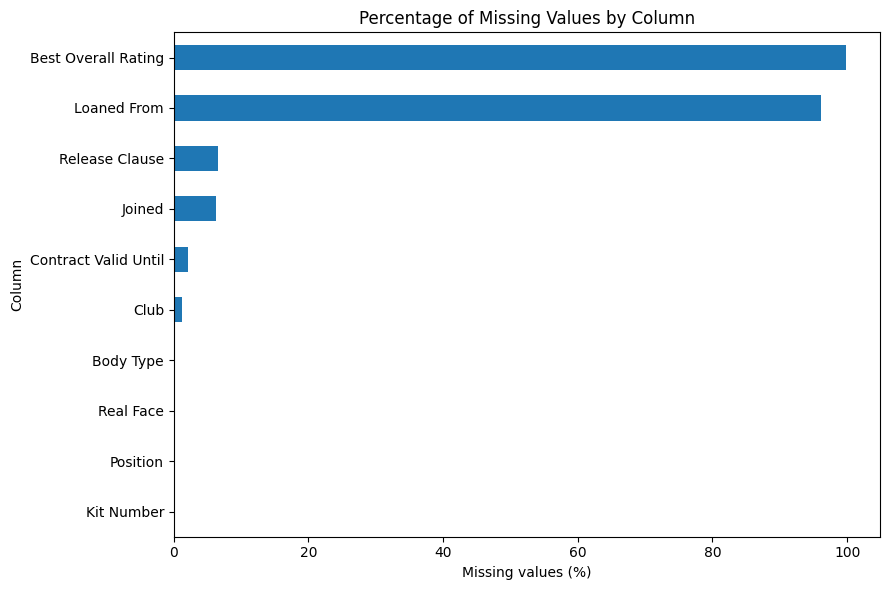

In [14]:
missing_to_plot = missing_report[
    missing_report["Missing_Percentage"] > 0
]["Missing_Percentage"].sort_values()

missing_to_plot.plot(
    kind="barh",
    figsize=(9, 6),
    title="Percentage of Missing Values by Column"
)

plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

### Explanation: Plotting columns that contain missing values

**Purpose of this code:** This block filters the missing-value report and draws a horizontal bar chart.

#### Step-by-step explanation

1. `missing_report[missing_report["Missing_Percentage"] > 0]` keeps only rows where the missing percentage is greater than zero.
2. The following `["Missing_Percentage"]` selects only that percentage column from the filtered table.
3. `.sort_values()` arranges the percentages from small to large so the horizontal chart is easy to read.
4. `missing_to_plot.plot(...)` uses Pandas’ built-in plotting method.
5. `kind="barh"` requests horizontal bars. `figsize=(9, 6)` gives the figure width and height in inches. `title=...` sets the chart title.
6. `plt.xlabel()` and `plt.ylabel()` label the axes.
7. `plt.tight_layout()` adjusts spacing to reduce overlapping labels.
8. `plt.show()` displays the completed chart.

#### Syntax explained

- A comparison such as `> 0` produces Boolean values.
- Passing a Boolean Series inside `df[...]` is called Boolean filtering or Boolean indexing.
- The tuple `(9, 6)` stores two values: figure width and height.
- Keyword arguments make function settings explicit and readable.


## 6.2 Interpreting Missingness

Missing does not always mean incorrect.

Examples:

- `Loaned From` is missing for players who are not on loan;
- `Club` may be missing for free agents;
- `Release Clause` may not exist for every contract;
- `Best Overall Rating` is almost completely missing.

Possible actions:

- keep the value missing;
- replace it with a meaningful category;
- create a True/False indicator;
- fill it statistically;
- remove the column;
- remove affected rows.

We should not automatically replace every missing value with zero.

# 7. Data Cleaning

We now clean the working copy `df`.

The raw DataFrame remains unchanged.

## 7.1 Standardize Column Names

We replace spaces with underscores.

Example:

```text
Preferred Foot → Preferred_Foot
```

In [15]:
df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ", "_", regex=False)
)

print(df.columns.tolist())

['ID', 'Name', 'Age', 'Photo', 'Nationality', 'Flag', 'Overall', 'Potential', 'Club', 'Club_Logo', 'Value', 'Wage', 'Special', 'Preferred_Foot', 'International_Reputation', 'Weak_Foot', 'Skill_Moves', 'Work_Rate', 'Body_Type', 'Real_Face', 'Position', 'Joined', 'Loaned_From', 'Contract_Valid_Until', 'Height', 'Weight', 'Release_Clause', 'Kit_Number', 'Best_Overall_Rating']


### Explanation: Standardising column names

**Purpose of this code:** This code removes unwanted spaces around column names and replaces spaces inside names with underscores.

#### Step-by-step explanation

1. `df.columns = (...)` assigns a cleaned set of names back to the DataFrame’s column index.
2. `df.columns.str` gives access to Pandas string methods for every column name.
3. `.strip()` removes spaces at the beginning and end of each name.
4. `.replace(" ", "_", regex=False)` replaces ordinary spaces with underscores.
5. `regex=False` tells Pandas to treat the first argument as plain text rather than as a regular-expression pattern.
6. The final `print()` shows the updated list of names.

#### Syntax explained

- Parentheses allow a long expression to continue across several lines.
- A leading dot on the next line is a common style for method chaining.
- `" "` is a string containing one space; `"_"` is a string containing one underscore.


## 7.2 Represent Loan Status Correctly

Most players are not on loan, so `Loaned_From` is naturally missing for them.

We create:

```text
Is_Loaned
```

- `True`: a lending club is present;
- `False`: no lending club is listed.

In [16]:
df["Is_Loaned"] = df["Loaned_From"].notna()

df[["Name", "Club", "Loaned_From", "Is_Loaned"]].sample(
    8,
    random_state=7
)

,Name,Club,Loaned_From,Is_Loaned
15930,22 E. Young,Scunthorpe United,NaN,False
14340,J. Nekadio,Standard de Liège,NaN,False
14143,H. Lintott,Northampton Town,NaN,False
1706,Willian José,Real Betis Balompié,NaN,False
12797,A. Abdusalam,Zhejiang Professional FC,NaN,False
15107,C. Ravych,KSV Cercle Brugge,NaN,False
13779,22 M. Borgers,Türkgücü München,NaN,False
2646,C. Sapong,Nashville SC,NaN,False


### Explanation: Creating a Boolean loan-status column

**Purpose of this code:** This block derives a new `Is_Loaned` field and displays a reproducible sample.

#### Step-by-step explanation

1. `df["Loaned_From"].notna()` returns `True` when a player has a non-missing source club and `False` when the value is missing.
2. `df["Is_Loaned"] = ...` creates a new DataFrame column from those Boolean results.
3. `df[["Name", "Club", "Loaned_From", "Is_Loaned"]]` selects several columns. Two pairs of square brackets are used because the inner brackets contain a list of column names.
4. `.sample(8, random_state=7)` displays eight randomly selected rows and fixes the random result for reproducibility.

#### Syntax explained

- One column: `df["Name"]`. Several columns: `df[["Name", "Age"]]`.
- Boolean values are the special Python values `True` and `False`.
- Creating a new column uses the same assignment operator `=` used for ordinary variables.


## 7.3 Remove Columns Not Needed Here

We remove:

- image URL columns;
- the original loan-source column after creating `Is_Loaned`;
- `Best_Overall_Rating`, because it is almost entirely missing.

A removed column is not necessarily useless in every project. It is simply unnecessary for our current questions.

In [17]:
columns_to_drop = [
    "Photo",
    "Flag",
    "Club_Logo",
    "Loaned_From",
    "Best_Overall_Rating"
]

df = df.drop(columns=columns_to_drop)

print("Remaining number of columns:", df.shape[1])

Remaining number of columns: 25


### Explanation: Dropping unnecessary columns

**Purpose of this code:** This code stores a list of columns that are not needed for the classroom analysis and removes them from the working DataFrame.

#### Step-by-step explanation

1. `columns_to_drop = [...]` creates a Python list containing five column-name strings.
2. `df.drop(columns=columns_to_drop)` returns a new DataFrame without those columns.
3. `df = ...` stores that new DataFrame back in `df`.
4. `df.shape[1]` gets the second item of the shape tuple, which is the number of columns. Python indexing starts at zero, so index `1` means the second item.

#### Syntax explained

- Square brackets create a list and also select an item by position.
- `columns=...` tells `drop()` that the supplied labels refer to columns, not rows.
- Because `inplace=True` is not used, the returned DataFrame must be reassigned to `df`.


## 7.4 Clean the Position Column

The original values contain HTML text such as:

```html
<span class="pos pos15">LCM
```

We only want:

```text
LCM
```

A regular expression extracts the part after `>`.

In [16]:
print("Before:")
display(raw_df["Position"].head())

df["Position"] = (
    df["Position"]
    .astype("string")
    .str.extract(r">([^<]+)$", expand=False)
)

print("After:")
display(df["Position"].head())

Before:


0    <span class="pos pos28">SUB
1    <span class="pos pos15">LCM
2      <span class="pos pos7">LB
3    <span class="pos pos13">RCM
4    <span class="pos pos13">RCM
Name: Position, dtype: object

After:


0    SUB
1    LCM
2     LB
3    RCM
4    RCM
Name: Position, dtype: string

### Explanation: Cleaning the Position text

**Purpose of this code:** This block shows the original `Position` values, extracts the useful text from the HTML-like content, and then shows the cleaned values.

#### Step-by-step explanation

1. `display(raw_df["Position"].head())` shows the unmodified source values for comparison.
2. `df["Position"].astype("string")` converts the column to Pandas’ string data type so string operations are safe.
3. `.str.extract(r">([^<]+)$", expand=False)` applies a regular expression to each value.
4. In the pattern, `>` matches a greater-than character, `([^<]+)` captures one or more characters that are not `<`, and `$` requires the captured text to be at the end of the string.
5. `expand=False` requests a Series instead of a one-column DataFrame.
6. The cleaned Series is assigned back to `df["Position"]` and the final display shows the result.

#### Syntax explained

- The prefix `r` creates a raw string, which is useful for regular expressions because backslashes are treated literally.
- Parentheses in a regular expression create a capture group.
- `+` in this regular expression means “one or more of the preceding pattern.”
- Assignment to an existing DataFrame column replaces that column’s values.


## 7.5 Convert Currency Text into Numbers

The dataset contains values such as:

```text
€91M
€115K
€500
```

We convert them to:

```text
91,000,000
115,000
500
```

The reusable function below:

1. removes `€`;
2. detects `M` or `K`;
3. applies the correct multiplier;
4. returns a numerical value.

In [18]:
def parse_euro_value(value):
    # Convert FIFA currency text to a numerical euro value.
    if pd.isna(value):
        return np.nan

    text = str(value).strip()
    text = text.replace("€", "").replace(",", "")

    multiplier = 1

    if text.endswith("M"):
        multiplier = 1_000_000
        text = text[:-1]
    elif text.endswith("K"):
        multiplier = 1_000
        text = text[:-1]

    try:
        return float(text) * multiplier
    except ValueError:
        return np.nan


currency_columns = ["Value", "Wage", "Release_Clause"]

for column in currency_columns:
    df[f"{column}_EUR"] = df[column].apply(parse_euro_value)

df[[
    "Value", "Value_EUR",
    "Wage", "Wage_EUR",
    "Release_Clause", "Release_Clause_EUR"
]].head()

,Value,Value_EUR,Wage,Wage_EUR,Release_Clause,Release_Clause_EUR
0,€91M,91000000.0,€115K,115000.0,€157M,157000000.0
1,€78.5M,78500000.0,€190K,190000.0,€155M,155000000.0
2,€46.5M,46500000.0,€46K,46000.0,€97.7M,97700000.0
3,€107.5M,107500000.0,€350K,350000.0,€198.9M,198900000.0
4,€89.5M,89500000.0,€110K,110000.0,€154.4M,154400000.0


### Explanation: Converting FIFA currency text to numbers

**Purpose of this code:** This block defines a reusable function that converts values such as `€110.5M` or `€500K` into ordinary euro amounts, then applies it to three columns.

#### Step-by-step explanation

1. `def parse_euro_value(value):` defines a function named `parse_euro_value` with one input parameter called `value`. The colon begins the indented function body.
2. The line beginning with `#` is a comment. Python ignores comments when running the code.
3. `if pd.isna(value): return np.nan` immediately returns a missing numerical value when the input is missing.
4. `text = str(value).strip()` converts the input to text and removes spaces at both ends.
5. `text.replace("€", "").replace(",", "")` removes the euro sign and commas. The second `replace()` is chained to the result of the first.
6. `multiplier = 1` creates a default multiplier for values with no `K` or `M` suffix.
7. `if text.endswith("M"):` checks whether the cleaned text ends with `M`. If it does, the multiplier becomes one million.
8. `text = text[:-1]` removes the final character. The slice `[:-1]` means “from the beginning up to, but not including, the last character.”
9. `elif text.endswith("K"):` checks the second possible condition only when the first `if` condition was false. It uses a multiplier of one thousand.
10. `try:` marks code that might fail. `float(text)` attempts to convert the remaining text to a decimal number.
11. `except ValueError:` catches a conversion failure and returns `np.nan` instead of stopping the notebook.
12. `currency_columns = [...]` stores the three source columns in a list.
13. `for column in currency_columns:` repeats the indented instruction once for each column name.
14. `df[f"{column}_EUR"]` uses an f-string to create names such as `Value_EUR` and `Wage_EUR`.
15. `.apply(parse_euro_value)` sends every value in the source column through the custom function.
16. The final multi-column selection displays the original and converted values side by side.

#### Syntax explained

- `def` creates a function; `return` sends a result back to the place where the function was called.
- Underscores inside numbers, such as `1_000_000`, improve readability and do not change the numerical value.
- `elif` means “else if.”
- A `try ... except` block handles expected errors safely.
- A `for` loop repeats its indented body for each item in a sequence.
- String slicing uses `text[start:stop]`; omitted positions mean the beginning or end.


## 7.6 Convert Height and Weight

We extract the numerical parts from values such as:

```text
189cm
82kg
```

New columns:

- `Height_cm`;
- `Weight_kg`.

In [19]:
df["Height_cm"] = pd.to_numeric(
    df["Height"].astype(str).str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

df["Weight_kg"] = pd.to_numeric(
    df["Weight"].astype(str).str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

df[["Height", "Height_cm", "Weight", "Weight_kg"]].head()

,Height,Height_cm,Weight,Weight_kg
0,189cm,189,82kg,82
1,179cm,179,69kg,69
2,172cm,172,69kg,69
3,181cm,181,70kg,70
4,172cm,172,68kg,68


### Explanation: Extracting numerical height and weight

**Purpose of this code:** This code removes unit text from height and weight values and converts the extracted parts into numeric columns.

#### Step-by-step explanation

1. `df["Height"].astype(str)` converts every value in the `Height` column to ordinary Python text.
2. `.str.extract(r"(\d+\.?\d*)")` extracts the first number. In the regular expression, `\d+` means one or more digits, `\.?` means an optional decimal point, and `\d*` means zero or more additional digits.
3. `[0]` selects the first captured column returned by `extract()`.
4. `pd.to_numeric(..., errors="coerce")` converts the extracted strings to numbers. Values that cannot be converted become missing (`NaN`) instead of raising an error.
5. The same process is repeated for weight.
6. The final line selects original and cleaned columns so students can compare them.

#### Syntax explained

- Regular expressions are compact text-search patterns.
- `errors="coerce"` is a safe conversion option that changes invalid input into a missing value.
- The code is split across lines inside parentheses, but Python treats it as one statement.


## 7.7 Convert Dates and Contract Years

`pd.to_datetime()` converts ordinary text to a date type.

The contract field has mixed formats, so we extract a four-digit year.

In [20]:
df["Joined_Date"] = pd.to_datetime(
    df["Joined"],
    errors="coerce"
)

df["Contract_End_Year"] = pd.to_numeric(
    df["Contract_Valid_Until"]
    .astype("string")
    .str.extract(r"(\d{4})")[0],
    errors="coerce"
).astype("Int64")

display(df[["Joined", "Joined_Date"]].head())

display(
    df[["Contract_Valid_Until", "Contract_End_Year"]]
    .sample(8, random_state=15)
)

,Joined,Joined_Date
0,"Jul 1, 2018",2018-07-01
1,"Jan 30, 2020",2020-01-30
2,"Sep 14, 2020",2020-09-14
3,"Aug 30, 2015",2015-08-30
4,"Sep 1, 2020",2020-09-01


,Contract_Valid_Until,Contract_End_Year
558,NaN,<NA>
1511,2024,2024
6619,2024,2024
485,2022,2022
1103,2024,2024
14124,2023,2023
905,2024,2024
2606,2025,2025


### Explanation: Converting joined dates and contract years

**Purpose of this code:** This block creates a proper date column and extracts a four-digit contract-ending year.

#### Step-by-step explanation

1. `pd.to_datetime(df["Joined"], errors="coerce")` tries to interpret every `Joined` value as a date. Invalid or missing values become `NaT`, Pandas’ missing-date marker.
2. The converted values are stored in a new column called `Joined_Date`.
3. For `Contract_End_Year`, the original column is converted to Pandas string data and `.str.extract(r"(\d{4})")` captures exactly four digits.
4. `[0]` selects the captured Series, and `pd.to_numeric(..., errors="coerce")` converts it into numbers.
5. `.astype("Int64")` uses Pandas’ nullable integer type. Unlike ordinary NumPy integers, `Int64` can contain missing values.
6. The first `display()` shows the original and converted joined dates.
7. The second `display()` shows a reproducible sample of original contract text and extracted years.

#### Syntax explained

- `\d{4}` means exactly four digits in a regular expression.
- `NaT` stands for “Not a Time” and represents a missing date.
- `Int64` with a capital `I` is Pandas’ nullable integer type.
- A function can be called over several lines when its arguments are inside parentheses.


## 7.8 Handle Selected Missing Categories

For some text columns, a label is clearer than a blank value.

We use:

```text
Unknown / Free Agent
Unknown
```

We do not force missing release clauses or dates to zero, because zero would have a different meaning.

In [21]:
df["Club"] = df["Club"].fillna("Unknown / Free Agent")

for column in ["Position", "Body_Type", "Real_Face"]:
    df[column] = df[column].fillna("Unknown")

rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
rows_after = len(df)

print("Rows before duplicate removal:", rows_before)
print("Rows after duplicate removal:", rows_after)
print("Rows removed:", rows_before - rows_after)

Rows before duplicate removal: 17660
Rows after duplicate removal: 17660
Rows removed: 0


### Explanation: Filling selected missing values and removing duplicate rows

**Purpose of this code:** This block replaces missing labels with readable text, removes duplicate rows, and reports how many rows were removed.

#### Step-by-step explanation

1. `df["Club"].fillna("Unknown / Free Agent")` replaces missing club values with a descriptive label.
2. The `for` loop repeats the same `fillna("Unknown")` operation for `Position`, `Body_Type`, and `Real_Face`.
3. `rows_before = len(df)` stores the number of rows before duplicate removal.
4. `df.drop_duplicates()` removes repeated complete rows.
5. `.reset_index(drop=True)` creates a new sequential row index. `drop=True` prevents the old index from becoming a normal column.
6. `rows_after = len(df)` stores the new row count.
7. `rows_before - rows_after` calculates how many rows were removed.

#### Syntax explained

- `len(df)` returns the number of DataFrame rows.
- The loop variable `column` temporarily holds one column name during each repetition.
- Subtraction uses `-`.
- Method chaining allows duplicate removal and index resetting in one statement.


## 7.9 Validate Important Ranges

Validation checks help identify impossible values.

They do not prove that every value is perfectly accurate, but they can reveal obvious problems.

In [22]:
validation_checks = {
    "Age between 15 and 50": df["Age"].between(15, 50).all(),
    "Overall between 0 and 100": df["Overall"].between(0, 100).all(),
    "Potential between 0 and 100": df["Potential"].between(0, 100).all(),
    "Height between 140 and 220 cm": df["Height_cm"].between(140, 220).all(),
    "Weight between 40 and 130 kg": df["Weight_kg"].between(40, 130).all()
}

pd.Series(validation_checks, name="Passed")

Age between 15 and 50            False
Overall between 0 and 100         True
Potential between 0 and 100       True
Height between 140 and 220 cm     True
Weight between 40 and 130 kg      True
Name: Passed, dtype: bool

### Explanation: Running simple validation checks

**Purpose of this code:** This code tests whether important numerical columns stay inside expected ranges and presents the results as a labelled Series.

#### Step-by-step explanation

1. `validation_checks = {...}` creates a dictionary. Each key is a readable test description, and each value is the Boolean result of that test.
2. `df["Age"].between(15, 50)` returns `True` or `False` for every age depending on whether it lies inside the inclusive range.
3. `.all()` returns `True` only when every value in the Series is `True`.
4. The same pattern checks overall rating, potential, height, and weight.
5. `pd.Series(validation_checks, name="Passed")` converts the dictionary into a one-dimensional labelled Pandas object and names the result column `Passed`.

#### Syntax explained

- A dictionary can store computed values, not only fixed text or numbers.
- `.between(a, b)` includes both endpoints by default.
- `.all()` reduces many Boolean values to one overall Boolean answer.
- One failed check does not automatically mean the dataset is unusable; it tells us where to investigate.


# 8. Feature Engineering

Feature engineering means creating new useful variables from existing data.

In [23]:
# Potential improvement available in the game
df["Growth_Potential"] = df["Potential"] - df["Overall"]

# More readable financial units
df["Value_Million_EUR"] = df["Value_EUR"] / 1_000_000
df["Wage_Thousand_EUR"] = df["Wage_EUR"] / 1_000

# BMI is included only as a mathematical feature-engineering example
df["BMI"] = (
    df["Weight_kg"] /
    ((df["Height_cm"] / 100) ** 2)
)

# Age groups
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 20, 24, 29, 34, 100],
    labels=[
        "20 or younger",
        "21-24",
        "25-29",
        "30-34",
        "35+"
    ]
)

# Rating groups
df["Rating_Category"] = pd.cut(
    df["Overall"],
    bins=[0, 59, 69, 79, 89, 100],
    labels=[
        "Below 60",
        "60-69",
        "70-79",
        "80-89",
        "90+"
    ]
)

df[[
    "Name",
    "Age",
    "Age_Group",
    "Overall",
    "Potential",
    "Growth_Potential",
    "Value_Million_EUR",
    "Wage_Thousand_EUR",
    "BMI",
    "Rating_Category"
]].head()

,Name,Age,Age_Group,Overall,Potential,Growth_Potential,Value_Million_EUR,Wage_Thousand_EUR,BMI,Rating_Category
0,L. Goretzka,27,25-29,87,88,1,91.0,115.0,22.955684,80-89
1,Bruno Fernandes,27,25-29,86,87,1,78.5,190.0,21.534908,80-89
2,M. Acuña,30,30-34,85,85,0,46.5,46.0,23.323418,80-89
3,K. De Bruyne,31,30-34,91,91,0,107.5,350.0,21.366869,90+
4,N. Barella,25,25-29,86,89,3,89.5,110.0,22.985398,80-89


### Explanation: Engineering new features

**Purpose of this code:** This block creates useful variables from existing columns: growth potential, easier financial units, BMI, age groups, and rating groups.

#### Step-by-step explanation

1. Lines beginning with `#` are comments that divide the block into logical sections.
2. `df["Potential"] - df["Overall"]` subtracts the two columns row by row to measure possible rating improvement.
3. Dividing `Value_EUR` by `1_000_000` converts euros to millions of euros. Dividing wages by `1_000` converts them to thousands of euros.
4. BMI is calculated as weight in kilograms divided by height in metres squared. `df["Height_cm"] / 100` converts centimetres to metres, `** 2` squares the result, and the outer division is performed row by row.
5. `pd.cut()` divides continuous ages into categories. The `bins` list defines the boundary points, while the `labels` list supplies names for the resulting intervals.
6. The age bins produce five categories, so five labels are supplied.
7. A second `pd.cut()` call creates categories from overall ratings.
8. The final column selection displays the source variables and new features together.

#### Syntax explained

- Arithmetic on Pandas columns is vectorised: the operation is applied to every row without writing a loop.
- `/` means division, `-` means subtraction, and `**` means exponentiation.
- `pd.cut()` is used to convert numerical values into ranges or categories.
- The order of labels must match the order of intervals created by the bin boundaries.


## Important BMI limitation

BMI does not directly measure football ability, athletic performance, body composition, or muscle quality.

It is included only to demonstrate how a new numerical variable can be calculated.

# 9. Exploratory Data Analysis

Exploratory Data Analysis, or **EDA**, means studying data before formal modelling.

EDA includes:

- descriptive statistics;
- filtering;
- sorting;
- grouping;
- charts;
- relationship analysis;
- interpretation.

In [24]:
analysis_columns = [
    "Age",
    "Overall",
    "Potential",
    "Growth_Potential",
    "Value_Million_EUR",
    "Wage_Thousand_EUR",
    "Height_cm",
    "Weight_kg",
    "BMI"
]

df[analysis_columns].describe().round(2)

,Age,Overall,Potential,Growth_Potential,Value_Million_EUR,Wage_Thousand_EUR,Height_cm,Weight_kg,BMI
count,17660.00,17660.00,17660.00,17660.00,17660.00,17660.00,17660.00,17660.00,17660.00
mean,23.13,63.37,70.98,7.61,2.74,8.19,180.89,74.33,22.69
std,4.64,8.04,6.53,5.75,7.84,20.48,6.96,6.98,1.37
min,15.00,43.00,42.00,-1.00,0.00,0.00,149.00,48.00,15.62
25%,20.00,58.00,67.00,2.00,0.32,0.55,176.00,70.00,21.80
50%,22.00,63.00,71.00,8.00,0.70,2.00,181.00,74.00,22.69
75%,26.00,69.00,75.00,12.00,1.72,6.00,186.00,79.00,23.53
max,54.00,91.00,95.00,26.00,190.50,450.00,206.00,110.00,34.72


### Explanation: Summarising selected analysis variables

**Purpose of this code:** This block creates a reusable list of numerical columns and calculates descriptive statistics for only those columns.

#### Step-by-step explanation

1. `analysis_columns = [...]` stores the chosen column names in a list.
2. `df[analysis_columns]` selects every column whose name is in that list.
3. `.describe()` calculates descriptive statistics for the selected numerical data.
4. `.round(2)` makes the output easier to read by keeping two decimal places.

#### Syntax explained

- Storing column names in a list avoids repeatedly typing a long multi-column selection.
- A variable containing a list can be passed inside DataFrame square brackets.
- Method chaining applies `describe()` first and `round()` second.


## 9.1 Age Distribution

A histogram divides numerical values into intervals called bins.

Questions:

- Where are most players concentrated?
- Is the distribution balanced?
- Are there unusually young or old players?

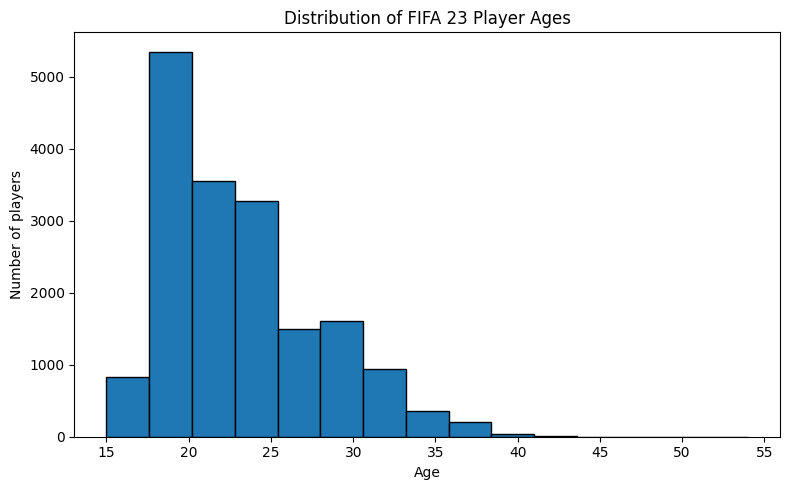

In [25]:
df["Age"].plot(
    kind="hist",
    bins=15,
    figsize=(8, 5),
    edgecolor="black",
    title="Distribution of FIFA 23 Player Ages"
)

plt.xlabel("Age")
plt.ylabel("Number of players")
plt.tight_layout()
plt.show()

### Explanation: Plotting a histogram of Age

**Purpose of this code:** This block draws a histogram to show how frequently different age values occur.

#### Step-by-step explanation

1. `df["Age"]` selects the `Age` column.
2. `.plot(...)` asks Pandas to create a chart from that Series.
3. `kind="hist"` selects a histogram. A histogram groups numerical values into intervals and counts how many observations fall in each interval.
4. `bins=15` requests 15 intervals. More bins show more detail; fewer bins give a smoother summary.
5. `figsize=(8, 5)` sets the figure dimensions, and `edgecolor="black"` adds borders around the bars.
6. `title="Distribution of FIFA 23 Player Ages"` places a title above the chart.
7. `plt.xlabel("Age")` labels the horizontal axis, while `plt.ylabel("Number of players")` labels the vertical axis.
8. `plt.tight_layout()` improves spacing and `plt.show()` displays the figure.

#### Syntax explained

- A histogram is suitable for one numerical variable.
- Named plotting options are passed as keyword arguments.
- The chart is created by Pandas but further customised through `plt`, the Matplotlib alias.


## 9.2 Overall Rating Distribution

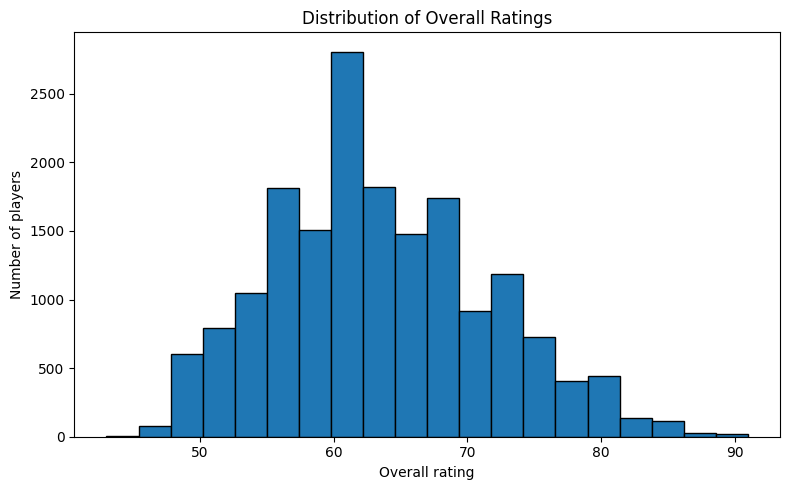

In [26]:
df["Overall"].plot(
    kind="hist",
    bins=20,
    figsize=(8, 5),
    edgecolor="black",
    title="Distribution of Overall Ratings"
)

plt.xlabel("Overall rating")
plt.ylabel("Number of players")
plt.tight_layout()
plt.show()

### Explanation: Plotting a histogram of Overall

**Purpose of this code:** This block draws a histogram to show how frequently different overall values occur.

#### Step-by-step explanation

1. `df["Overall"]` selects the `Overall` column.
2. `.plot(...)` asks Pandas to create a chart from that Series.
3. `kind="hist"` selects a histogram. A histogram groups numerical values into intervals and counts how many observations fall in each interval.
4. `bins=20` requests 20 intervals. More bins show more detail; fewer bins give a smoother summary.
5. `figsize=(8, 5)` sets the figure dimensions, and `edgecolor="black"` adds borders around the bars.
6. `title="Distribution of Overall Ratings"` places a title above the chart.
7. `plt.xlabel("Overall rating")` labels the horizontal axis, while `plt.ylabel("Number of players")` labels the vertical axis.
8. `plt.tight_layout()` improves spacing and `plt.show()` displays the figure.

#### Syntax explained

- A histogram is suitable for one numerical variable.
- Named plotting options are passed as keyword arguments.
- The chart is created by Pandas but further customised through `plt`, the Matplotlib alias.


## 9.3 Highest-Rated Players

`sort_values()` arranges the rows.

`ascending=False` places the highest values first.

In [27]:
top_rated_players = (
    df.sort_values(
        ["Overall", "Potential"],
        ascending=[False, False]
    )
    [[
        "Name",
        "Age",
        "Nationality",
        "Club",
        "Position",
        "Overall",
        "Potential",
        "Value_Million_EUR"
    ]]
    .head(15)
)

top_rated_players

,Name,Age,Nationality,Club,Position,Overall,Potential,Value_Million_EUR
75,K. Mbappé,23,France,Paris Saint-Germain,"<span class=""pos pos25"">ST",91,95,190.5
3,K. De Bruyne,31,Belgium,Manchester City,"<span class=""pos pos13"">RCM",91,91,107.5
41,R. Lewandowski,33,Poland,FC Barcelona,"<span class=""pos pos25"">ST",91,91,84.0
56,L. Messi,35,Argentina,Paris Saint-Germain,"<span class=""pos pos23"">RW",91,91,54.0
124,K. Benzema,34,France,Real Madrid CF,"<span class=""pos pos21"">CF",91,91,64.0
14357,T. Courtois,30,Belgium,Real Madrid CF,"<span class=""pos pos0"">GK",90,91,90.0
25,M. Salah,30,Egypt,Liverpool,"<span class=""pos pos23"">RW",90,90,115.5
100,Cristiano Ronaldo,37,Portugal,Manchester United,"<span class=""pos pos25"">ST",90,90,41.0
192,V. van Dijk,30,Netherlands,Liverpool,"<span class=""pos pos6"">LCB",90,90,98.0
9151,M. Neuer,36,Germany,FC Bayern München,"<span class=""pos pos0"">GK",90,90,13.5


### Explanation: Finding the highest-rated players

**Purpose of this code:** This code sorts players by rating and potential, selects useful display columns, and keeps the first 15 rows.

#### Step-by-step explanation

1. `df.sort_values(["Overall", "Potential"], ascending=[False, False])` sorts first by `Overall` and uses `Potential` to break ties.
2. The two-element `ascending` list corresponds to the two sort columns. `False` means descending order for each column.
3. The following double-bracket section selects only the listed columns and preserves their specified order.
4. `.head(15)` keeps the first 15 rows after sorting.
5. The whole chain is wrapped in parentheses and stored as `top_rated_players`.
6. The final line displays that DataFrame.

#### Syntax explained

- When several sort columns are supplied, Pandas applies them from left to right.
- A list of Boolean values can control the direction for each sort column.
- Parentheses allow a readable multi-line method chain without backslashes.


## 9.4 Young High-Potential Players

For this lesson, a young talent is defined as:

- age 21 or younger;
- potential rating of at least 85.

This is a classroom rule, not a universal football definition.

In [28]:
young_talents = (
    df[
        (df["Age"] <= 21) &
        (df["Potential"] >= 85)
    ]
    .sort_values(
        ["Potential", "Overall"],
        ascending=False
    )
    [[
        "Name",
        "Age",
        "Nationality",
        "Club",
        "Overall",
        "Potential",
        "Growth_Potential",
        "Value_Million_EUR"
    ]]
)

young_talents.head(20)

,Name,Age,Nationality,Club,Overall,Potential,Growth_Potential,Value_Million_EUR
180,E. Haaland,21,Norway,Manchester City,88,94,6,148.0
214,Pedri,19,Spain,FC Barcelona,85,93,8,116.0
849,Vinícius Jr.,21,Brazil,Real Madrid CF,86,92,6,109.0
70,J. Bellingham,19,England,Borussia Dortmund,84,91,7,81.5
795,F. Wirtz,19,Germany,Bayer 04 Leverkusen,82,91,9,66.0
698,J. Musiala,19,Germany,FC Bayern München,81,90,9,55.5
953,22 M. Greenwood,19,England,Manchester United,79,90,11,38.0
1544,Ansu Fati,19,Spain,FC Barcelona,79,90,11,38.0
86,A. Davies,21,Canada,FC Bayern München,84,89,5,60.5
247,B. Saka,20,England,Arsenal,82,89,7,60.5


### Explanation: Filtering young high-potential players

**Purpose of this code:** This block finds players aged 21 or younger with potential of at least 85, sorts them, and displays the first 20.

#### Step-by-step explanation

1. `df["Age"] <= 21` creates one Boolean condition for age.
2. `df["Potential"] >= 85` creates a second Boolean condition for potential.
3. The `&` operator combines the conditions and means that both must be true. Each condition is placed in parentheses because Pandas Boolean expressions require clear grouping.
4. `df[combined_condition]` filters the rows.
5. `.sort_values(["Potential", "Overall"], ascending=False)` sorts both columns from highest to lowest.
6. The double-bracket selection chooses the columns to show.
7. `young_talents.head(20)` displays the first 20 filtered and sorted players.

#### Syntax explained

- `<=` means less than or equal to; `>=` means greater than or equal to.
- For Pandas Series, use `&` for element-by-element “and,” not Python’s ordinary `and` keyword.
- Every condition joined with `&` should be surrounded by parentheses.


## 9.5 Players with the Greatest Growth Potential

In [29]:
highest_growth_players = (
    df.sort_values(
        ["Growth_Potential", "Potential"],
        ascending=False
    )
    [[
        "Name",
        "Age",
        "Club",
        "Overall",
        "Potential",
        "Growth_Potential",
        "Value_Million_EUR"
    ]]
    .head(20)
)

highest_growth_players

,Name,Age,Club,Overall,Potential,Growth_Potential,Value_Million_EUR
14483,22 K. Smith,16,Dundee United,57,83,26,0.625
12373,D. Lobban,16,Aberdeen,53,79,26,0.375
14989,E. Mayenda,17,FC Sochaux-Montbéliard,53,79,26,0.375
8409,22 D. Gore,16,Manchester United,57,82,25,0.500
16520,22 P. Lervik,16,Molde FK,57,82,25,0.475
15205,J. Feeney,17,Aston Villa,55,80,25,0.375
15169,L. Harvey,17,Aberdeen,53,78,25,0.300
14675,22 A. Denholm,17,Heart of Midlothian,52,77,25,0.250
17450,22 C. Walsh,16,Sligo Rovers,52,77,25,0.230
15365,F. Valencia,17,Inter Miami CF,50,75,25,0.150


### Explanation: Finding players with the greatest growth potential

**Purpose of this code:** This block ranks players by the newly engineered growth measure and returns the top 20.

#### Step-by-step explanation

1. `sort_values(["Growth_Potential", "Potential"], ascending=False)` ranks rows by growth potential and then by potential as a tie-breaker.
2. The following column list controls exactly what appears in the result.
3. `.head(20)` keeps only the first 20 rows after sorting.
4. The final expression displays `highest_growth_players`.

#### Syntax explained

- A tie-breaker is a second sort column used when rows have the same value in the first sort column.
- `ascending=False` applies descending order to all supplied sort columns when a single Boolean is used.


## 9.6 Preferred Foot

`value_counts()` counts the frequency of every category.

`normalize=True` converts counts to proportions.

In [30]:
preferred_foot_summary = pd.DataFrame({
    "Count": df["Preferred_Foot"].value_counts(),
    "Percentage": (
        df["Preferred_Foot"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
})

preferred_foot_summary

,Count,Percentage
Preferred_Foot,,
Right,13651,77.3
Left,4009,22.7


### Explanation: Summarising preferred-foot counts and percentages

**Purpose of this code:** This code creates a table showing both the number and percentage of right-footed and left-footed players.

#### Step-by-step explanation

1. `df["Preferred_Foot"].value_counts()` counts how many times each distinct category occurs.
2. `value_counts(normalize=True)` returns proportions instead of raw counts.
3. `.mul(100)` multiplies each proportion by 100. It is equivalent to `* 100` but works as a method in a chain.
4. `.round(2)` keeps two decimal places.
5. `pd.DataFrame({...})` combines the count Series and percentage Series into two columns.
6. The final line displays the summary table.

#### Syntax explained

- `normalize=True` changes counts into relative frequencies whose total is approximately 1.
- Dictionary keys become output column names.
- Pandas aligns Series by their index labels when building the DataFrame.


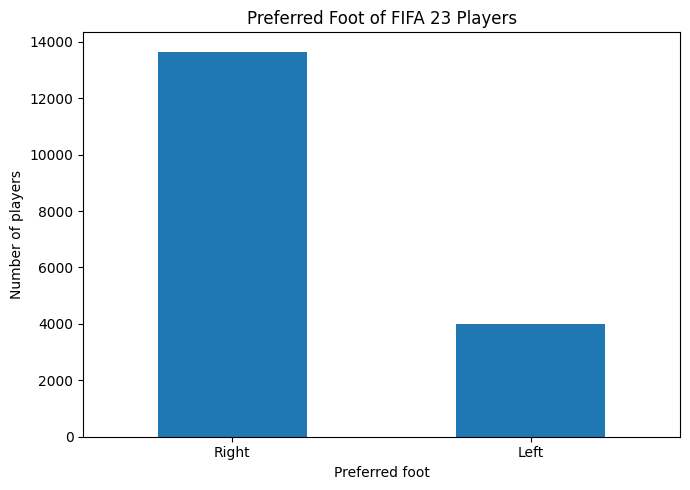

In [31]:
df["Preferred_Foot"].value_counts().plot(
    kind="bar",
    figsize=(7, 5),
    title="Preferred Foot of FIFA 23 Players"
)

plt.xlabel("Preferred foot")
plt.ylabel("Number of players")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Explanation: Plotting preferred-foot categories

**Purpose of this code:** This block counts preferred-foot categories and displays them as a vertical bar chart.

#### Step-by-step explanation

1. `value_counts()` produces the height of each bar.
2. `.plot(kind="bar", ...)` requests a vertical bar chart.
3. `figsize=(7, 5)` sets the chart size and `title=...` sets its heading.
4. `plt.xticks(rotation=0)` keeps category labels horizontal instead of rotating them.
5. The remaining Matplotlib calls label the axes, adjust spacing, and display the chart.

#### Syntax explained

- Bar charts are useful for categorical counts.
- `rotation=0` means zero degrees of text rotation.
- The result of `value_counts()` is a Series that can be plotted directly.


## 9.7 Most Common Nationalities

This represents the players included in the dataset. It does not represent the total football population of each country.

Nationality
England          1531
Germany          1038
Spain             990
France            864
Argentina         843
Brazil            539
Italy             517
Netherlands       455
Uruguay           417
Japan             378
Venezuela         348
United States     345
Ecuador           344
Portugal          338
Poland            328
Name: count, dtype: int64

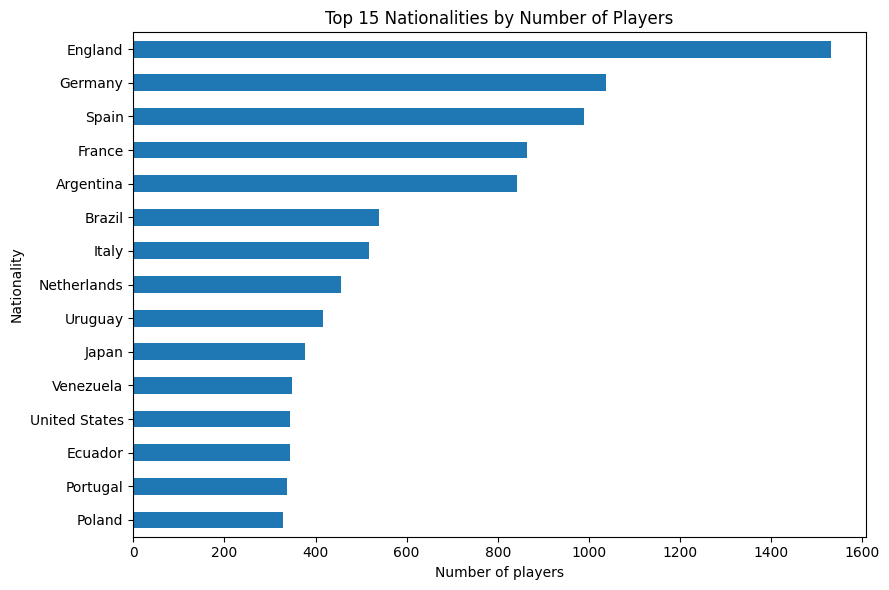

In [32]:
top_nationalities = df["Nationality"].value_counts().head(15)

display(top_nationalities)

top_nationalities.sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title="Top 15 Nationalities by Number of Players"
)

plt.xlabel("Number of players")
plt.ylabel("Nationality")
plt.tight_layout()
plt.show()

### Explanation: Finding and plotting the most common nationalities

**Purpose of this code:** This code identifies the 15 nationalities with the most players and plots them horizontally.

#### Step-by-step explanation

1. `value_counts()` counts players per nationality.
2. `.head(15)` keeps the 15 largest counts because `value_counts()` sorts descending by default.
3. `display(top_nationalities)` shows the numerical table before plotting.
4. `top_nationalities.sort_values()` sorts the counts from low to high for the horizontal chart, placing the largest bar near the top.
5. `kind="barh"` creates horizontal bars.
6. The final calls add axis labels, improve layout, and show the chart.

#### Syntax explained

- A Series produced by `value_counts()` has category labels as its index and counts as its values.
- Calling `sort_values()` without arguments uses ascending order by default.


## 9.8 Clubs with the Most Listed Players

Club
Manchester United          66
Arsenal                    47
FC Barcelona               46
Atlético de Madrid         45
Newcastle United           45
Wolverhampton Wanderers    44
Chelsea                    42
Gangwon FC                 42
Roma                       41
PSV                        41
Caracas Fútbol Club        41
Real Madrid CF             40
Paris Saint-Germain        39
Aston Villa                39
Olympique de Marseille     39
Name: count, dtype: int64

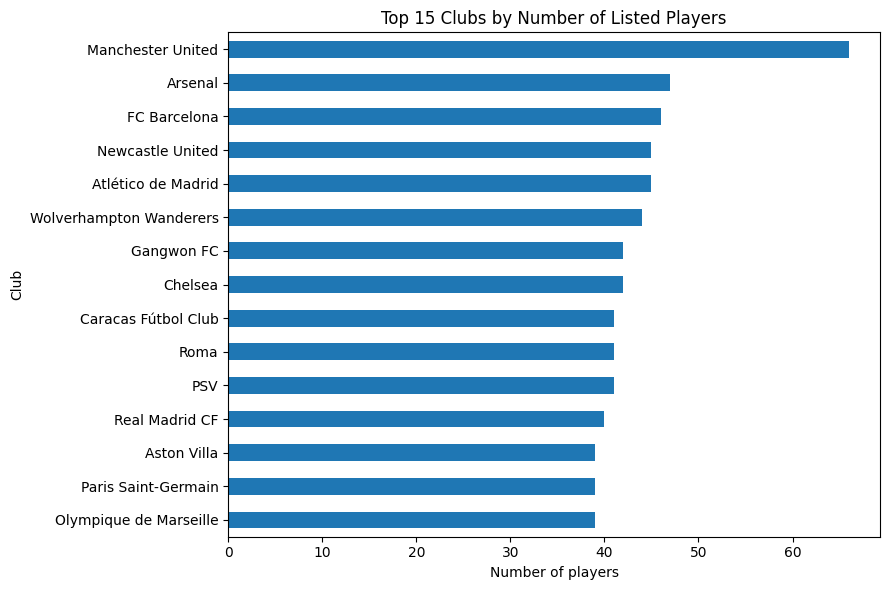

In [33]:
top_clubs_by_count = (
    df["Club"]
    .value_counts()
    .drop(labels=["Unknown / Free Agent"], errors="ignore")
    .head(15)
)

display(top_clubs_by_count)

top_clubs_by_count.sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title="Top 15 Clubs by Number of Listed Players"
)

plt.xlabel("Number of players")
plt.ylabel("Club")
plt.tight_layout()
plt.show()

### Explanation: Finding and plotting clubs with the most listed players

**Purpose of this code:** This block counts players per club, removes the placeholder free-agent category, and plots the top 15 clubs.

#### Step-by-step explanation

1. `df["Club"].value_counts()` counts players for each club.
2. `.drop(labels=["Unknown / Free Agent"], errors="ignore")` removes the placeholder label.
3. `errors="ignore"` prevents an error if that label is not present.
4. `.head(15)` keeps the 15 largest club counts.
5. The result is displayed, sorted upward for plotting, and drawn as a horizontal bar chart.
6. Axis labels, layout adjustment, and `show()` complete the chart.

#### Syntax explained

- `drop(labels=[...])` removes index labels from a Series.
- Method chains can be placed inside parentheses and broken across lines for readability.
- A horizontal chart is often easier to read when category names are long.


## 9.9 Summary by Age Group

`groupby()` separates the rows into groups.

`agg()` calculates several statistics for every group.

In [34]:
age_group_summary = (
    df.groupby(
        "Age_Group",
        observed=False
    )
    .agg(
        Player_Count=("ID", "count"),
        Average_Overall=("Overall", "mean"),
        Average_Potential=("Potential", "mean"),
        Average_Value_Million_EUR=("Value_Million_EUR", "mean"),
        Average_Growth=("Growth_Potential", "mean")
    )
    .round(2)
    .reset_index()
)

age_group_summary

,Age_Group,Player_Count,Average_Overall,Average_Potential,Average_Value_Million_EUR,Average_Growth
0,20 or younger,6181,57.67,71.19,0.83,13.51
1,21-24,5888,63.57,71.17,2.91,7.60
2,25-29,3565,68.61,70.26,4.97,1.65
3,30-34,1626,70.81,70.89,4.77,0.09
4,35+,400,71.56,71.79,1.71,0.23


### Explanation: Aggregating statistics by age group

**Purpose of this code:** This block groups players into the previously created age categories and calculates several summary measures for each category.

#### Step-by-step explanation

1. `df.groupby("Age_Group", observed=False)` forms one group for every age-category label.
2. `observed=False` tells Pandas to retain all defined categorical groups, even if a category has no rows.
3. `.agg(...)` calculates several named summaries in one operation.
4. `Player_Count=("ID", "count")` means: create an output column named `Player_Count` by counting non-missing `ID` values.
5. The other named aggregations calculate means for overall rating, potential, value, and growth.
6. `.round(2)` rounds numerical summaries.
7. `.reset_index()` changes `Age_Group` from the grouped index back into a normal DataFrame column.
8. The final line displays the summary.

#### Syntax explained

- `groupby()` follows the “split, apply, combine” idea: split rows into groups, apply calculations, then combine results.
- Named aggregation syntax is `New_Name=("Source_Column", "function")`.
- `mean` calculates an average; `count` counts non-missing values.


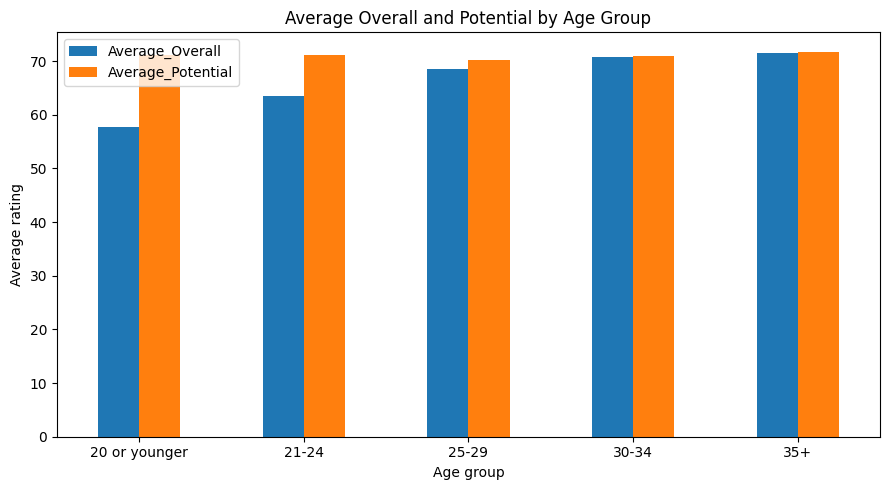

In [35]:
age_group_summary.plot(
    x="Age_Group",
    y=["Average_Overall", "Average_Potential"],
    kind="bar",
    figsize=(9, 5),
    title="Average Overall and Potential by Age Group"
)

plt.xlabel("Age group")
plt.ylabel("Average rating")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Explanation: Comparing average overall and potential by age group

**Purpose of this code:** This code plots two summary columns side by side for every age group.

#### Step-by-step explanation

1. `age_group_summary.plot(...)` plots the already aggregated table.
2. `x="Age_Group"` chooses the category column for the horizontal axis.
3. `y=["Average_Overall", "Average_Potential"]` supplies two numerical columns, producing two bars per age group.
4. `kind="bar"` creates a grouped vertical bar chart.
5. `plt.xticks(rotation=0)` keeps the age-group labels horizontal.
6. The other calls set labels, adjust spacing, and display the chart.

#### Syntax explained

- The `y` argument accepts a list when several series should be drawn on the same axes.
- A grouped bar chart is useful for comparing several measures across categories.


## 9.10 Age and Overall Rating

A scatter plot shows one point for each player.

Look for:

- direction;
- strength;
- clusters;
- unusual points.

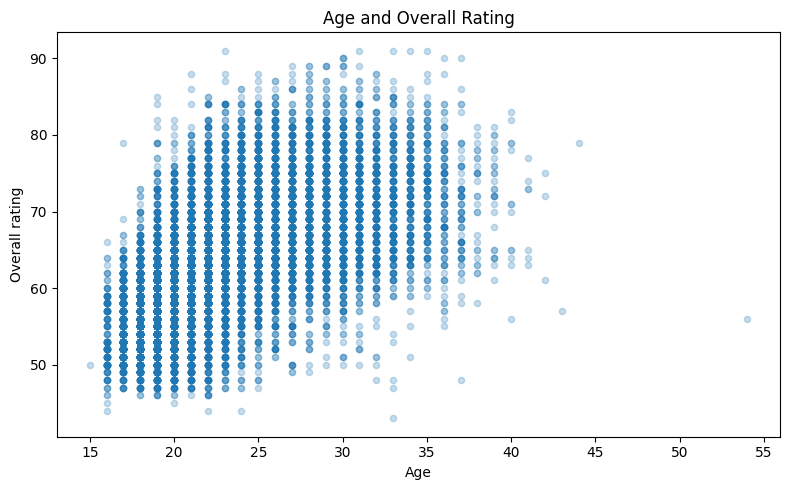

In [36]:
df.plot(
    x="Age",
    y="Overall",
    kind="scatter",
    alpha=0.25,
    figsize=(8, 5),
    title="Age and Overall Rating"
)

plt.xlabel("Age")
plt.ylabel("Overall rating")
plt.tight_layout()
plt.show()

### Explanation: Creating a scatter plot of Age and Overall

**Purpose of this code:** This block draws one point per player to examine the relationship between two numerical variables.

#### Step-by-step explanation

1. `df.plot(...)` creates a chart directly from the DataFrame.
2. `x="Age"` chooses the horizontal variable and `y="Overall"` chooses the vertical variable.
3. `kind="scatter"` requests a scatter plot.
4. `alpha=0.25` makes points partly transparent. Transparency helps reveal dense areas where many points overlap.
5. `figsize=(8, 5)` sets the figure size and `title=...` adds the chart title.
6. The Matplotlib calls label the x-axis and y-axis (`Overall rating`), improve spacing, and display the plot.

#### Syntax explained

- Scatter plots are designed for relationships between two numerical variables.
- `alpha` ranges from 0 (fully transparent) to 1 (fully opaque).
- Each row of the DataFrame contributes one plotted point when both selected values are available.


## 9.11 Overall Rating and Market Value

Player values are highly uneven: a small group has extremely high market values.

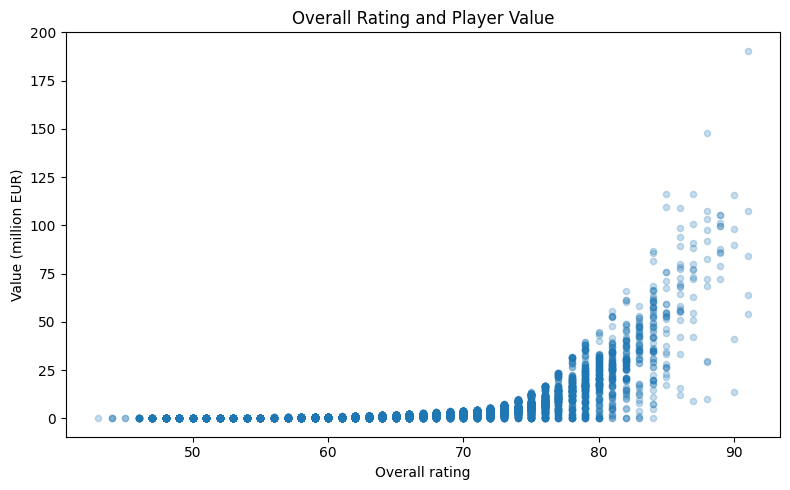

In [37]:
df.plot(
    x="Overall",
    y="Value_Million_EUR",
    kind="scatter",
    alpha=0.25,
    figsize=(8, 5),
    title="Overall Rating and Player Value"
)

plt.xlabel("Overall rating")
plt.ylabel("Value (million EUR)")
plt.tight_layout()
plt.show()

### Explanation: Creating a scatter plot of Overall and Value_Million_EUR

**Purpose of this code:** This block draws one point per player to examine the relationship between two numerical variables.

#### Step-by-step explanation

1. `df.plot(...)` creates a chart directly from the DataFrame.
2. `x="Overall"` chooses the horizontal variable and `y="Value_Million_EUR"` chooses the vertical variable.
3. `kind="scatter"` requests a scatter plot.
4. `alpha=0.25` makes points partly transparent. Transparency helps reveal dense areas where many points overlap.
5. `figsize=(8, 5)` sets the figure size and `title=...` adds the chart title.
6. The Matplotlib calls label the x-axis and y-axis (`Value (million EUR)`), improve spacing, and display the plot.

#### Syntax explained

- Scatter plots are designed for relationships between two numerical variables.
- `alpha` ranges from 0 (fully transparent) to 1 (fully opaque).
- Each row of the DataFrame contributes one plotted point when both selected values are available.


## 9.12 Club-Level Summary

A club with only one or two players could have an unstable average.

We keep clubs with at least 15 listed players.

In [38]:
club_summary = (
    df.groupby("Club")
    .agg(
        Player_Count=("ID", "count"),
        Average_Overall=("Overall", "mean"),
        Average_Potential=("Potential", "mean"),
        Total_Value_Million_EUR=("Value_Million_EUR", "sum")
    )
    .round(2)
    .reset_index()
)

top_clubs_by_average = (
    club_summary[
        (club_summary["Player_Count"] >= 15) &
        (club_summary["Club"] != "Unknown / Free Agent")
    ]
    .sort_values("Average_Overall", ascending=False)
    .head(15)
)

top_clubs_by_average

,Club,Player_Count,Average_Overall,Average_Potential,Total_Value_Million_EUR
484,Inter,33,78.67,81.42,802.43
24,AFC Richmond,15,78.07,80.47,290.60
877,Villarreal CF,25,78.04,81.80,485.32
630,Paris Saint-Germain,39,77.90,82.26,1098.05
497,Juventus,32,77.75,82.72,649.75
334,FC Bayern München,33,77.39,82.55,1045.40
13,AC Milan,32,77.31,81.91,670.72
589,Napoli,24,76.58,80.38,436.00
556,Manchester City,34,76.47,83.62,1258.60
726,SL Benfica,32,76.41,80.31,402.10


### Explanation: Comparing clubs by average player rating

**Purpose of this code:** This code creates club-level statistics and then keeps established clubs with at least 15 listed players, ranked by average overall rating.

#### Step-by-step explanation

1. `df.groupby("Club")` forms a group for each club.
2. `.agg(...)` creates player count, average overall, average potential, and total squad value summaries.
3. `Total_Value_Million_EUR=("Value_Million_EUR", "sum")` adds player values within each club.
4. The grouped result is rounded and its index is reset.
5. The second expression filters `club_summary` with two conditions: player count of at least 15 and club name not equal to the free-agent placeholder.
6. `&` requires both conditions to be true.
7. The filtered clubs are sorted by `Average_Overall` in descending order, and `.head(15)` keeps the top 15.

#### Syntax explained

- `!=` means “not equal to.”
- `sum` adds values, while `mean` calculates their average.
- Filtering aggregated data works the same way as filtering the original DataFrame.


## 9.13 Possible Bargain Players

For this classroom example, a possible bargain player must satisfy:

- age 25 or younger;
- overall rating at least 75;
- growth potential at least 4;
- value no more than €25 million.

The thresholds are subjective and can be changed.

In [39]:
bargain_players = (
    df[
        (df["Age"] <= 25) &
        (df["Overall"] >= 75) &
        (df["Growth_Potential"] >= 4) &
        (df["Value_Million_EUR"] <= 25)
    ]
    .sort_values(
        ["Overall", "Growth_Potential"],
        ascending=False
    )
    [[
        "Name",
        "Age",
        "Club",
        "Position",
        "Overall",
        "Potential",
        "Growth_Potential",
        "Value_Million_EUR",
        "Wage_Thousand_EUR"
    ]]
)

bargain_players.head(20)

,Name,Age,Club,Position,Overall,Potential,Growth_Potential,Value_Million_EUR,Wage_Thousand_EUR
911,20 Gabriel Barbosa,22,Inter,"<span class=""pos pos29"">RES",81,85,4,23.5,71.0
15561,J. Bijlow,24,Feyenoord,"<span class=""pos pos0"">GK",79,85,6,22.5,9.0
15912,Luís Maximiano,23,Lazio,"<span class=""pos pos0"">GK",79,85,6,22.5,32.0
462,M. Cash,24,Aston Villa,"<span class=""pos pos3"">RB",79,84,5,24.5,65.0
565,Y. Fofana,23,AS Monaco,"<span class=""pos pos11"">LDM",79,84,5,24.5,43.0
1093,Fran Beltrán,23,RC Celta de Vigo,"<span class=""pos pos10"">CDM",79,84,5,24.5,22.0
1368,J. Foyth,24,Villarreal CF,"<span class=""pos pos3"">RB",79,84,5,24.5,29.0
3780,Kim Min Jae,25,Napoli,"<span class=""pos pos6"">LCB",79,84,5,23.0,49.0
4386,Luiz Felipe,25,Real Betis Balompié,"<span class=""pos pos6"">LCB",79,84,5,23.0,25.0
222,R. Bentancur,25,Tottenham Hotspur,"<span class=""pos pos13"">RCM",79,83,4,24.5,85.0


### Explanation: Finding possible bargain players

**Purpose of this code:** This block applies four rules to identify young, strong, improving players whose estimated value is no more than 25 million euros.

#### Step-by-step explanation

1. Four Boolean conditions are created for age, overall rating, growth potential, and value.
2. The `&` operators combine them, so every selected row must satisfy all four rules.
3. The filtered rows are sorted by overall rating and then growth potential, both from high to low.
4. A multi-column selection keeps the player details relevant to the bargain-player question.
5. `bargain_players.head(20)` displays the first 20 matches.

#### Syntax explained

- `<=` includes the boundary value; a player valued exactly at 25 million is allowed.
- Complex filters are easier to understand when each condition is written on its own line.
- Parentheses around each condition are required when combining Pandas Series with `&`.


# 10. Correlation Analysis

Correlation measures the direction and strength of a linear relationship.

Its value ranges from `-1` to `+1`.

- near `+1`: strong positive relationship;
- near `-1`: strong negative relationship;
- near `0`: weak linear relationship.

## Warning

Correlation does not prove causation.

In [40]:
correlation_columns = [
    "Age",
    "Overall",
    "Potential",
    "Growth_Potential",
    "Special",
    "International_Reputation",
    "Weak_Foot",
    "Skill_Moves",
    "Height_cm",
    "Weight_kg",
    "Value_Million_EUR",
    "Wage_Thousand_EUR"
]

correlation_matrix = df[correlation_columns].corr().round(2)

correlation_matrix

,Age,Overall,Potential,Growth_Potential,Special,International_Reputation,Weak_Foot,Skill_Moves,Height_cm,Weight_kg,Value_Million_EUR,Wage_Thousand_EUR
Age,1.00,0.60,-0.03,-0.87,0.38,0.42,0.13,0.20,0.07,0.24,0.17,0.29
Overall,0.60,1.00,0.71,-0.60,0.70,0.48,0.26,0.44,0.06,0.16,0.56,0.60
Potential,-0.03,0.71,1.00,0.15,0.49,0.33,0.22,0.34,0.04,0.03,0.51,0.48
Growth_Potential,-0.87,-0.60,0.15,1.00,-0.42,-0.30,-0.12,-0.23,-0.03,-0.20,-0.21,-0.29
Special,0.38,0.70,0.49,-0.42,1.00,0.32,0.37,0.73,-0.30,-0.19,0.39,0.42
International_Reputation,0.42,0.48,0.33,-0.30,0.32,1.00,0.16,0.23,0.05,0.12,0.53,0.62
Weak_Foot,0.13,0.26,0.22,-0.12,0.37,0.16,1.00,0.36,-0.13,-0.09,0.17,0.19
Skill_Moves,0.20,0.44,0.34,-0.23,0.73,0.23,0.36,1.00,-0.36,-0.28,0.29,0.31
Height_cm,0.07,0.06,0.04,-0.03,-0.30,0.05,-0.13,-0.36,1.00,0.76,0.03,0.05
Weight_kg,0.24,0.16,0.03,-0.20,-0.19,0.12,-0.09,-0.28,0.76,1.00,0.06,0.08


### Explanation: Calculating a correlation matrix

**Purpose of this code:** This code selects numerical variables and calculates the pairwise linear correlation between every pair.

#### Step-by-step explanation

1. `correlation_columns = [...]` stores the chosen numerical column names.
2. `df[correlation_columns]` creates a smaller DataFrame containing only those variables.
3. `.corr()` calculates Pearson correlation coefficients by default.
4. A coefficient close to `1` indicates a strong positive linear relationship, close to `-1` indicates a strong negative linear relationship, and close to `0` indicates little linear relationship.
5. `.round(2)` keeps two decimal places.
6. The final line displays the square correlation table.

#### Syntax explained

- Correlation does not prove that one variable causes another.
- The diagonal values are 1 because every variable is perfectly correlated with itself.
- The matrix is symmetric: the correlation of A with B equals the correlation of B with A.


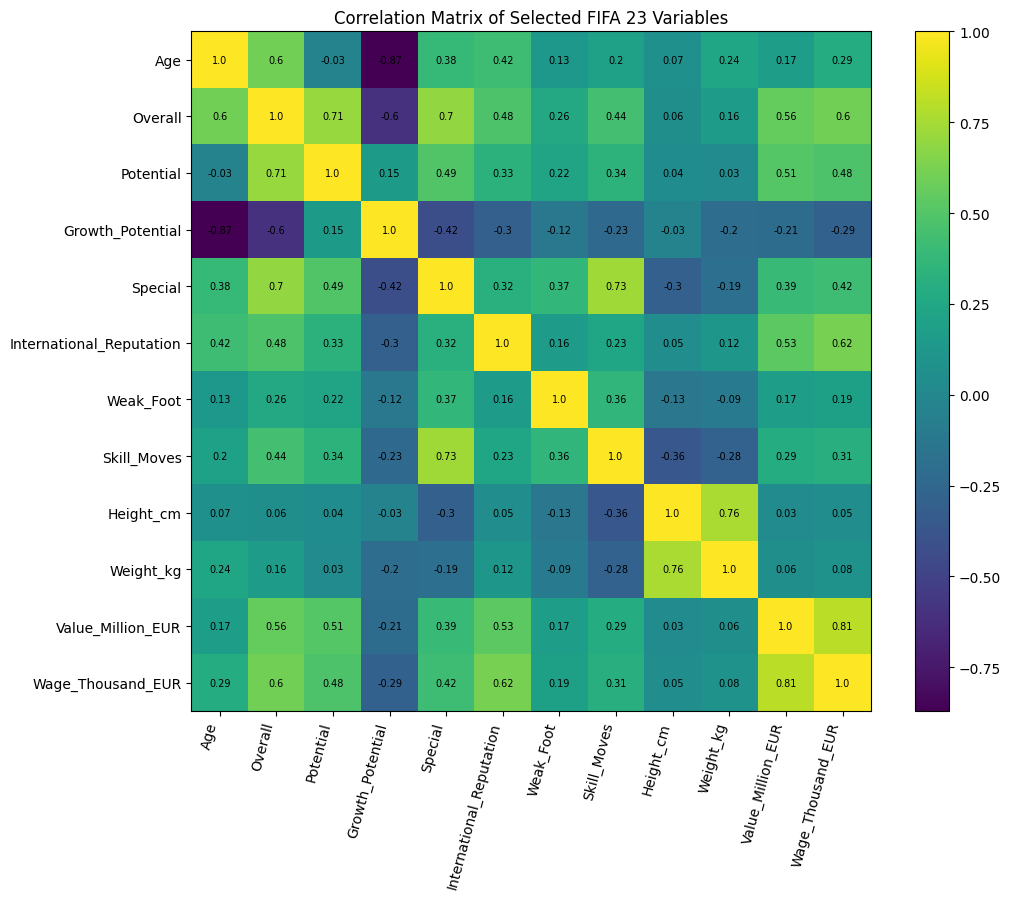

In [41]:
fig, ax = plt.subplots(figsize=(11, 9))

image = ax.imshow(correlation_matrix)

ax.set_xticks(range(len(correlation_columns)))
ax.set_yticks(range(len(correlation_columns)))

ax.set_xticklabels(
    correlation_columns,
    rotation=75,
    ha="right"
)

ax.set_yticklabels(correlation_columns)

for row in range(len(correlation_columns)):
    for column in range(len(correlation_columns)):
        ax.text(
            column,
            row,
            correlation_matrix.iloc[row, column],
            ha="center",
            va="center",
            fontsize=7
        )

fig.colorbar(image)
ax.set_title("Correlation Matrix of Selected FIFA 23 Variables")
plt.tight_layout()
plt.show()

### Explanation: Drawing an annotated correlation heatmap

**Purpose of this code:** This block turns the correlation matrix into a colour image and writes each coefficient inside its cell.

#### Step-by-step explanation

1. `fig, ax = plt.subplots(figsize=(11, 9))` creates a figure and one plotting area. Tuple unpacking stores them in `fig` and `ax`.
2. `ax.imshow(correlation_matrix)` displays the matrix as a colour-coded image and returns an image object stored in `image`.
3. `range(len(correlation_columns))` creates integer positions from 0 up to the number of columns minus one.
4. `set_xticks()` and `set_yticks()` place tick marks at those positions.
5. `set_xticklabels()` replaces the numerical positions with variable names. `rotation=75` rotates them, and `ha="right"` right-aligns the text.
6. `set_yticklabels()` labels the vertical axis with the same variable names.
7. The nested `for` loops visit every row-column combination in the matrix.
8. `correlation_matrix.iloc[row, column]` retrieves one coefficient by integer position.
9. `ax.text(...)` writes that coefficient at the corresponding heatmap cell. Horizontal and vertical alignment are centred, and `fontsize=7` keeps the text compact.
10. `fig.colorbar(image)` adds a scale explaining how colours correspond to values.
11. The final lines set the title, adjust spacing, and show the heatmap.

#### Syntax explained

- A nested loop is a loop inside another loop. The inner loop completes all columns for each row.
- `range(n)` produces 0, 1, 2, ..., `n-1`.
- `.iloc[row, column]` selects by integer position rather than by label.
- The `fig` object represents the complete figure; `ax` represents one set of axes inside it.


### Checkpoint

Answer:

1. Which age range contains most players?
2. Who are the highest-rated players?
3. Which young players have the highest potential?
4. Which nationality appears most often?
5. Which preferred foot is more common?
6. How do overall and potential change across age groups?
7. Which variables correlate strongly with overall rating?
8. Why does correlation not prove causation?

# 11. Preparing a Machine-Learning Problem

We will predict:

```text
Overall
```

This is a **regression problem** because the target is numerical.

## Target

The target is the value the model tries to predict.

## Features

Features are the input variables.

We use:

- Age;
- Potential;
- Special;
- International Reputation;
- Weak Foot;
- Skill Moves;
- Height;
- Weight.

We do not use value and wage because they are closely connected to player rating and market status.

## Limitation

`Special` is already an aggregate game statistic. It may contain substantial information related to `Overall`. The model is therefore educational, not an independent scouting model.

In [42]:
feature_columns = [
    "Age",
    "Potential",
    "Special",
    "International_Reputation",
    "Weak_Foot",
    "Skill_Moves",
    "Height_cm",
    "Weight_kg"
]

target_column = "Overall"

X = df[feature_columns]
y = df[target_column]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in model features:")
print(X.isna().sum())

display(X.head())

Feature shape: (17660, 8)
Target shape: (17660,)

Missing values in model features:
Age                         0
Potential                   0
Special                     0
International_Reputation    0
Weak_Foot                   0
Skill_Moves                 0
Height_cm                   0
Weight_kg                   0
dtype: int64


,Age,Potential,Special,International_Reputation,Weak_Foot,Skill_Moves,Height_cm,Weight_kg
0,27,88,2312,4.0,4.0,3.0,189,82
1,27,87,2305,3.0,3.0,4.0,179,69
2,30,85,2303,2.0,3.0,3.0,172,69
3,31,91,2303,4.0,5.0,4.0,181,70
4,25,89,2296,3.0,3.0,3.0,172,68


### Explanation: Preparing features and the target variable

**Purpose of this code:** This block defines the inputs used to predict a player’s overall rating and separates them from the target output.

#### Step-by-step explanation

1. `feature_columns = [...]` lists the eight predictor variables.
2. `target_column = "Overall"` stores the name of the value the model will learn to predict.
3. `X = df[feature_columns]` creates the feature matrix. By convention, machine-learning input data is named uppercase `X`.
4. `y = df[target_column]` creates the target Series. By convention, the output is named lowercase `y`.
5. `X.shape` reports rows and feature columns, while `y.shape` reports the number of target values.
6. `X.isna().sum()` counts missing values in each feature.
7. `display(X.head())` shows the first five feature rows.

#### Syntax explained

- Features are the input variables; the target is the output the model attempts to predict.
- `X` is two-dimensional because it has rows and columns. `y` is one-dimensional.
- Python variable names are case-sensitive, so `X` and `x` would be different variables.


## 11.1 Train-Test Split

We divide the dataset into:

- **training data**: used to learn the model;
- **test data**: used to evaluate the model on unseen rows.

We use:

- 80% training;
- 20% testing.

`random_state=42` makes the split reproducible.

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 14128
Testing rows: 3532


### Explanation: Splitting data into training and testing sets

**Purpose of this code:** This code reserves part of the data for final evaluation and uses the remaining part to train the model.

#### Step-by-step explanation

1. `train_test_split(X, y, ...)` splits the features and target together so corresponding rows remain aligned.
2. The function returns four objects, which are unpacked into training features, testing features, training targets, and testing targets.
3. `test_size=0.20` assigns 20% of the rows to the test set and the remaining 80% to the training set.
4. `random_state=42` makes the split reproducible.
5. `len(X_train)` and `len(X_test)` print the number of rows in each subset.

#### Syntax explained

- Training data is used to learn model parameters; testing data is kept separate to evaluate performance on unseen rows.
- A decimal such as `0.20` represents 20%.
- Multiple assignment allows four returned values to be stored in four variables.


# 12. Building the Machine-Learning Pipeline

A pipeline performs several steps in the correct order.

Our pipeline contains:

1. median imputation for missing numerical values;
2. standardization;
3. linear regression.

## Median imputation

The median is the middle value after sorting.

## Standardization

Standardization places variables on comparable scales.

## Linear regression

Linear regression estimates the target as a weighted combination of the features.

In [44]:
model_pipeline = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LinearRegression()
    )
])

model_pipeline.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


### Explanation: Building and training a machine-learning pipeline

**Purpose of this code:** This block creates a three-step workflow for handling missing values, scaling features, and fitting linear regression.

#### Step-by-step explanation

1. `Pipeline(steps=[...])` creates an ordered sequence of data-processing and modelling steps.
2. Each step is a tuple containing a step name and a transformer or model object.
3. `SimpleImputer(strategy="median")` replaces missing feature values with the median calculated from the training data.
4. `StandardScaler()` transforms each feature so it is centred around zero with a standard deviation near one.
5. `LinearRegression()` creates the regression model that learns a linear relationship between features and overall rating.
6. `model_pipeline.fit(X_train, y_train)` runs the steps in order: learn imputation values, learn scaling values, transform the training features, and fit the regression model.
7. The final `print()` confirms that training finished.

#### Syntax explained

- A tuple such as `("imputer", object)` groups a step name and its object.
- The square brackets contain the ordered list of pipeline steps.
- `fit()` means “learn from training data.”
- Using a pipeline helps prevent inconsistent preprocessing and reduces the risk of data leakage.


# 13. Model Prediction and Evaluation

We evaluate with:

## Mean Absolute Error

Average absolute difference between actual and predicted ratings.

Lower is better.

## Root Mean Squared Error

Similar to MAE, but gives more weight to large errors.

Lower is better.

## R-squared

Measures how much target variation is explained by the model.

- `1.0`: perfect fit;
- `0.0`: similar to predicting a constant mean;
- negative: worse than that simple baseline.

In [45]:
y_pred = model_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

model_metrics = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error",
        "Root Mean Squared Error",
        "R-squared"
    ],
    "Value": [
        mae,
        rmse,
        r2
    ]
})

model_metrics.round(3)

,Metric,Value
0,Mean Absolute Error,1.906
1,Root Mean Squared Error,2.420
2,R-squared,0.907


### Explanation: Making predictions and calculating model metrics

**Purpose of this code:** This block predicts overall ratings for the test set, calculates three evaluation measures, and stores them in a table.

#### Step-by-step explanation

1. `model_pipeline.predict(X_test)` applies the trained preprocessing steps and model to unseen test features.
2. The predicted ratings are stored in `y_pred`.
3. `mean_absolute_error(y_test, y_pred)` calculates the average absolute difference between actual and predicted ratings.
4. `mean_squared_error(...)` calculates the average squared error. `np.sqrt(...)` then takes its square root to obtain RMSE in the original rating units.
5. `r2_score(...)` calculates R-squared, which measures how much variation in the target is explained by the model relative to a mean prediction.
6. `pd.DataFrame({...})` creates a two-column metric table from parallel lists of names and values.
7. `model_metrics.round(3)` displays the results rounded to three decimal places.

#### Syntax explained

- `predict()` uses an already fitted model; it does not retrain the model.
- MAE and RMSE are lower-is-better error measures. R-squared is generally higher-is-better.
- `np.sqrt()` is NumPy’s square-root function.


## 13.1 Compare with a Simple Baseline

The baseline predicts the training-set average rating for every test player.

A useful model should perform better than this baseline.

In [46]:
baseline_predictions = np.full(
    shape=len(y_test),
    fill_value=y_train.mean()
)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)
baseline_r2 = r2_score(y_test, baseline_predictions)

comparison = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Linear Regression Pipeline"
    ],
    "MAE": [
        baseline_mae,
        mae
    ],
    "RMSE": [
        baseline_rmse,
        rmse
    ],
    "R2": [
        baseline_r2,
        r2
    ]
})

comparison.round(3)

,Model,MAE,RMSE,R2
0,Mean Baseline,6.426,7.947,-0.000
1,Linear Regression Pipeline,1.906,2.420,0.907


### Explanation: Comparing the model with a simple baseline

**Purpose of this code:** This code creates a baseline that predicts the training-set mean for every test player and compares it with the regression pipeline.

#### Step-by-step explanation

1. `np.full(shape=len(y_test), fill_value=y_train.mean())` creates an array with one value per test row.
2. Every entry is filled with the average training target, producing a simple “always predict the mean” baseline.
3. The same MAE, RMSE, and R-squared functions are used to evaluate the baseline.
4. `comparison = pd.DataFrame({...})` creates one row for the baseline and one row for the linear regression pipeline.
5. The lists under `MAE`, `RMSE`, and `R2` are aligned by position with the model-name list.
6. `comparison.round(3)` displays the comparison with three decimal places.

#### Syntax explained

- A baseline provides a minimum reference point; a useful model should improve clearly on it.
- `shape=` controls the output length of `np.full`, while `fill_value=` controls the repeated value.
- Baseline R-squared can be zero or negative depending on how predictions and evaluation data relate.


## 13.2 Actual vs Predicted Ratings

A perfect model would place every point on the diagonal reference line.

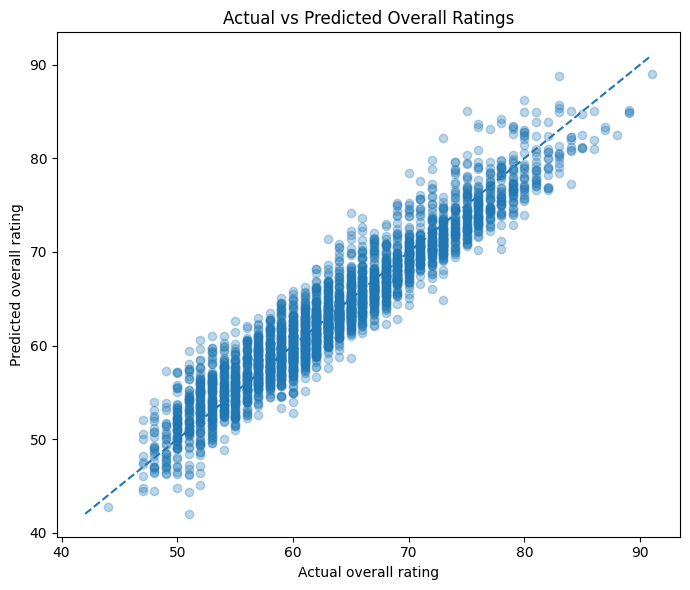

In [47]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.3
)

minimum_rating = min(y_test.min(), y_pred.min())
maximum_rating = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum_rating, maximum_rating],
    [minimum_rating, maximum_rating],
    linestyle="--"
)

plt.xlabel("Actual overall rating")
plt.ylabel("Predicted overall rating")
plt.title("Actual vs Predicted Overall Ratings")
plt.tight_layout()
plt.show()

### Explanation: Plotting actual ratings against predicted ratings

**Purpose of this code:** This block creates a diagnostic scatter plot and adds a diagonal reference line representing perfect predictions.

#### Step-by-step explanation

1. `plt.figure(figsize=(7, 6))` starts a new figure.
2. `plt.scatter(y_test, y_pred, alpha=0.3)` plots actual values on the horizontal axis and predicted values on the vertical axis.
3. `y_test.min()` and `y_pred.min()` find the smallest actual and predicted values; Python’s `min()` selects the smaller of those two.
4. The same pattern with `max()` finds the largest value needed for the reference line.
5. `plt.plot([minimum_rating, maximum_rating], [minimum_rating, maximum_rating], linestyle="--")` draws a line where predicted rating equals actual rating.
6. Points close to that diagonal line are accurate predictions; points far away have larger errors.
7. The remaining calls label the axes, add a title, improve spacing, and display the chart.

#### Syntax explained

- The two lists supplied to `plt.plot()` contain the x-coordinates and y-coordinates of the line endpoints.
- `linestyle="--"` requests a dashed line.
- A scatter plot does not automatically prove a model is unbiased; residual analysis can provide further evidence.


## 13.3 Model Coefficients and Largest Errors

A linear regression coefficient shows the direction and relative strength of the learned relationship.

Coefficients do not prove causation.

Large errors may indicate:

- unusual players;
- missing explanatory variables;
- model limitations;
- data-quality issues.

In [48]:
linear_model = model_pipeline.named_steps["model"]

coefficient_table = pd.DataFrame({
    "Feature": feature_columns,
    "Coefficient": linear_model.coef_
})

coefficient_table["Absolute_Coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

coefficient_table = coefficient_table.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

display(coefficient_table.round(3))

test_results = df.loc[X_test.index, [
    "Name",
    "Age",
    "Club",
    "Overall",
    "Potential"
]].copy()

test_results["Predicted_Overall"] = y_pred
test_results["Absolute_Error"] = (
    test_results["Overall"] -
    test_results["Predicted_Overall"]
).abs()

largest_errors = (
    test_results
    .sort_values("Absolute_Error", ascending=False)
    .head(15)
)

display(largest_errors.round(2))

,Feature,Coefficient,Absolute_Coefficient
1,Potential,5.026,5.026
0,Age,4.246,4.246
2,Special,1.791,1.791
7,Weight_kg,0.368,0.368
6,Height_cm,0.169,0.169
3,International_Reputation,-0.138,0.138
5,Skill_Moves,-0.079,0.079
4,Weak_Foot,-0.079,0.079


,Name,Age,Club,Overall,Potential,Predicted_Overall,Absolute_Error
3143,21 Hilton,42,Montpellier Hérault SC,75,75,85.06,10.06
2277,Rubén Castro,41,Málaga CF,73,73,82.18,9.18
15973,13 D. James,41,AFC Bournemouth,65,65,74.13,9.13
17411,22 M. Boylan,16,Lincoln City,51,57,42.05,8.95
14675,22 A. Denholm,17,Heart of Midlothian,52,77,60.57,8.57
5025,P. Jagielka,39,Stoke City,70,70,78.45,8.45
6044,D. Rodríguez,38,Hermanos Colmenarez,63,63,71.42,8.42
12049,22 L. Chipperfield,17,FC Basel 1893,51,74,59.40,8.40
15998,M. Campagna,18,Vancouver Whitecaps FC,49,72,57.34,8.34
5803,K. de la Fuente,20,Olympique de Marseille,73,77,64.87,8.13


### Explanation: Inspecting coefficients and the largest prediction errors

**Purpose of this code:** This block extracts the trained regression coefficients, ranks them by absolute size, and identifies test players with the largest errors.

#### Step-by-step explanation

1. `model_pipeline.named_steps["model"]` retrieves the pipeline step named `model`, which is the fitted `LinearRegression` object.
2. `linear_model.coef_` contains one learned coefficient for each feature. The trailing underscore is a Scikit-learn convention indicating an attribute learned during fitting.
3. A DataFrame is created by pairing feature names with coefficients.
4. `.abs()` converts every coefficient to its absolute magnitude so negative and positive effects can be compared by size.
5. The coefficient table is sorted by `Absolute_Coefficient` from largest to smallest and displayed.
6. `df.loc[X_test.index, [...]]` selects the original player rows whose index labels belong to the test set, together with chosen columns.
7. `.copy()` makes an independent result table before new columns are added.
8. `test_results["Predicted_Overall"] = y_pred` adds the predictions in the same test-row order.
9. The actual minus predicted difference is calculated row by row, and `.abs()` turns it into non-negative absolute error.
10. The table is sorted by error in descending order, `.head(15)` keeps the worst 15 predictions, and the result is displayed.

#### Syntax explained

- `.loc[row_labels, column_labels]` selects data by labels.
- An underscore at the end of a Scikit-learn attribute, such as `coef_`, usually means it was learned during `fit()`.
- A coefficient’s magnitude is affected by feature scaling; interpretation also depends on relationships among features.
- Absolute error ignores whether a prediction was too high or too low and measures only the size of the mistake.


# 14. Communication and Responsible Interpretation

A good data science report should include:

1. project question;
2. dataset description;
3. cleaning decisions;
4. major findings;
5. model performance;
6. limitations;
7. next steps.

## Limitations

- ratings come from a video game;
- some ratings may contain subjective judgement;
- the model uses variables produced by the same rating system;
- injuries, form, tactics, and match context are not included;
- correlation and prediction do not establish causality;
- ratings may become outdated.

In [49]:
summary_results = {
    "Number of players": len(df),
    "Average age": round(df["Age"].mean(), 2),
    "Average overall rating": round(df["Overall"].mean(), 2),
    "Highest overall rating": int(df["Overall"].max()),
    "Most common nationality": df["Nationality"].mode().iloc[0],
    "Most common preferred foot": df["Preferred_Foot"].mode().iloc[0],
    "Model MAE": round(mae, 2),
    "Model RMSE": round(rmse, 2),
    "Model R-squared": round(r2, 3)
}

pd.Series(summary_results, name="Result")

Number of players               17660
Average age                     23.13
Average overall rating          63.37
Highest overall rating             91
Most common nationality       England
Most common preferred foot      Right
Model MAE                        1.91
Model RMSE                       2.42
Model R-squared                 0.907
Name: Result, dtype: object

### Explanation: Creating a final results summary

**Purpose of this code:** This block collects important dataset and model results in a compact labelled Series.

#### Step-by-step explanation

1. `summary_results = {...}` creates a dictionary whose keys are result labels.
2. `len(df)` gives the number of players.
3. `df["Age"].mean()` and `df["Overall"].mean()` calculate averages, and `round(..., 2)` rounds them to two decimal places.
4. `df["Overall"].max()` finds the highest rating, and `int(...)` converts it to an ordinary integer.
5. `.mode()` returns the most frequent value or values. `.iloc[0]` selects the first mode by integer position.
6. The model metrics are also rounded and placed in the dictionary.
7. `pd.Series(summary_results, name="Result")` converts the dictionary into a labelled one-column result object.

#### Syntax explained

- Built-in Python functions used here include `len()`, `round()`, and `int()`.
- `.iloc[0]` means “select the first item by position.”
- Dictionary values can come from calculations performed at runtime.


# 15. Exporting the Cleaned Data

We save a practical set of cleaned columns to:

```text
FIFA23_cleaned_for_class.csv
```

The original CSV remains unchanged.

In [50]:
export_columns = [
    "ID",
    "Name",
    "Age",
    "Age_Group",
    "Nationality",
    "Club",
    "Position",
    "Overall",
    "Potential",
    "Growth_Potential",
    "Rating_Category",
    "Value_EUR",
    "Value_Million_EUR",
    "Wage_EUR",
    "Wage_Thousand_EUR",
    "Preferred_Foot",
    "International_Reputation",
    "Weak_Foot",
    "Skill_Moves",
    "Work_Rate",
    "Height_cm",
    "Weight_kg",
    "BMI",
    "Is_Loaned",
    "Joined_Date",
    "Contract_End_Year",
    "Release_Clause_EUR"
]

cleaned_export = df[export_columns].copy()

OUTPUT_FILE = Path("FIFA23_cleaned_for_class.csv")

cleaned_export.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8"
)

print("Cleaned CSV saved as:", OUTPUT_FILE)
print("Exported shape:", cleaned_export.shape)

Cleaned CSV saved as: FIFA23_cleaned_for_class.csv
Exported shape: (17660, 27)


### Explanation: Exporting the cleaned classroom dataset

**Purpose of this code:** This code selects the final columns, creates an export DataFrame, writes it to CSV, and reports the saved shape.

#### Step-by-step explanation

1. `export_columns = [...]` defines the exact columns and order for the exported file.
2. `cleaned_export = df[export_columns].copy()` selects those columns and creates an independent DataFrame.
3. `OUTPUT_FILE = Path("FIFA23_cleaned_for_class.csv")` stores the output path.
4. `cleaned_export.to_csv(...)` writes the table to a comma-separated-values file.
5. `index=False` prevents the DataFrame index from becoming an unwanted CSV column.
6. `encoding="utf-8"` uses a widely supported text encoding that can represent international characters.
7. The final two `print()` calls report the file path and exported dimensions.

#### Syntax explained

- CSV is a plain-text table format; each row is written on a line and fields are separated by commas.
- The uppercase variable name `OUTPUT_FILE` signals a configuration-style value.
- Selecting export columns explicitly prevents accidental inclusion of temporary columns.


In [51]:
verified_export = pd.read_csv(OUTPUT_FILE)

verified_export.head()

,ID,Name,Age,Age_Group,Nationality,Club,Position,Overall,Potential,Growth_Potential,...,Weak_Foot,Skill_Moves,Work_Rate,Height_cm,Weight_kg,BMI,Is_Loaned,Joined_Date,Contract_End_Year,Release_Clause_EUR
0,209658,L. Goretzka,27,25-29,Germany,FC Bayern München,"<span class=""pos pos28"">SUB",87,88,1,...,4.0,3.0,High/ Medium,189,82,22.955684,False,2018-07-01,2026.0,157000000.0
1,212198,Bruno Fernandes,27,25-29,Portugal,Manchester United,"<span class=""pos pos15"">LCM",86,87,1,...,3.0,4.0,High/ High,179,69,21.534908,False,2020-01-30,2026.0,155000000.0
2,224334,M. Acuña,30,30-34,Argentina,Sevilla FC,"<span class=""pos pos7"">LB",85,85,0,...,3.0,3.0,High/ High,172,69,23.323418,False,2020-09-14,2024.0,97700000.0
3,192985,K. De Bruyne,31,30-34,Belgium,Manchester City,"<span class=""pos pos13"">RCM",91,91,0,...,5.0,4.0,High/ High,181,70,21.366869,False,2015-08-30,2025.0,198900000.0
4,224232,N. Barella,25,25-29,Italy,Inter,"<span class=""pos pos13"">RCM",86,89,3,...,3.0,3.0,High/ High,172,68,22.985398,False,2020-09-01,2026.0,154400000.0


### Explanation: Reading the exported file back for verification

**Purpose of this code:** This block confirms that the saved CSV can be opened successfully.

#### Step-by-step explanation

1. `pd.read_csv(OUTPUT_FILE)` reads the file that was just created and stores it in `verified_export`.
2. `verified_export.head()` displays the first five rows so we can visually check the exported structure.

#### Syntax explained

- Reading a file after writing it is a simple verification step.
- The same `Path` object can be passed to both `to_csv()` and `read_csv()`.


# 16. Reusable DataFrame Inspection Function

A function groups reusable instructions under one name.

This function can be used with another CSV dataset.

In [52]:
def inspect_dataframe(dataframe):
    # Print a beginner-friendly DataFrame overview.
    print("SHAPE")
    print(
        f"Rows: {dataframe.shape[0]}, "
        f"Columns: {dataframe.shape[1]}"
    )

    print("\nCOLUMN NAMES")
    print(dataframe.columns.tolist())

    print("\nDATA TYPES")
    print(dataframe.dtypes)

    print("\nTOP MISSING-VALUE COUNTS")
    print(
        dataframe.isna()
        .sum()
        .sort_values(ascending=False)
        .head(10)
    )

    print("\nDUPLICATE ROWS")
    print(dataframe.duplicated().sum())

    print("\nFIRST FIVE ROWS")
    display(dataframe.head())


inspect_dataframe(verified_export)

SHAPE
Rows: 17660, Columns: 27

COLUMN NAMES
['ID', 'Name', 'Age', 'Age_Group', 'Nationality', 'Club', 'Position', 'Overall', 'Potential', 'Growth_Potential', 'Rating_Category', 'Value_EUR', 'Value_Million_EUR', 'Wage_EUR', 'Wage_Thousand_EUR', 'Preferred_Foot', 'International_Reputation', 'Weak_Foot', 'Skill_Moves', 'Work_Rate', 'Height_cm', 'Weight_kg', 'BMI', 'Is_Loaned', 'Joined_Date', 'Contract_End_Year', 'Release_Clause_EUR']

DATA TYPES
ID                            int64
Name                            str
Age                           int64
Age_Group                       str
Nationality                     str
Club                            str
Position                        str
Overall                       int64
Potential                     int64
Growth_Potential              int64
Rating_Category                 str
Value_EUR                   float64
Value_Million_EUR           float64
Wage_EUR                    float64
Wage_Thousand_EUR           float64
Preferred_Fo

,ID,Name,Age,Age_Group,Nationality,Club,Position,Overall,Potential,Growth_Potential,...,Weak_Foot,Skill_Moves,Work_Rate,Height_cm,Weight_kg,BMI,Is_Loaned,Joined_Date,Contract_End_Year,Release_Clause_EUR
0,209658,L. Goretzka,27,25-29,Germany,FC Bayern München,"<span class=""pos pos28"">SUB",87,88,1,...,4.0,3.0,High/ Medium,189,82,22.955684,False,2018-07-01,2026.0,157000000.0
1,212198,Bruno Fernandes,27,25-29,Portugal,Manchester United,"<span class=""pos pos15"">LCM",86,87,1,...,3.0,4.0,High/ High,179,69,21.534908,False,2020-01-30,2026.0,155000000.0
2,224334,M. Acuña,30,30-34,Argentina,Sevilla FC,"<span class=""pos pos7"">LB",85,85,0,...,3.0,3.0,High/ High,172,69,23.323418,False,2020-09-14,2024.0,97700000.0
3,192985,K. De Bruyne,31,30-34,Belgium,Manchester City,"<span class=""pos pos13"">RCM",91,91,0,...,5.0,4.0,High/ High,181,70,21.366869,False,2015-08-30,2025.0,198900000.0
4,224232,N. Barella,25,25-29,Italy,Inter,"<span class=""pos pos13"">RCM",86,89,3,...,3.0,3.0,High/ High,172,68,22.985398,False,2020-09-01,2026.0,154400000.0


### Explanation: Defining a reusable DataFrame inspection function

**Purpose of this code:** This block creates a function that prints a beginner-friendly overview of any DataFrame, then applies it to the verified export.

#### Step-by-step explanation

1. `def inspect_dataframe(dataframe):` defines a function with one parameter. The caller can pass any DataFrame through that parameter.
2. The comment explains the function’s purpose.
3. The first section prints a heading and then uses an f-string to display row and column counts.
4. `dataframe.shape[0]` is the row count, while `dataframe.shape[1]` is the column count.
5. Adjacent f-strings inside the same parentheses are automatically joined into one string.
6. The next sections print column names and data types.
7. For missing values, the method chain creates missing-value indicators, counts them, sorts from highest to lowest, and keeps the top ten.
8. `dataframe.duplicated().sum()` counts duplicate complete rows.
9. `display(dataframe.head())` presents the first five rows.
10. After the function definition ends, `inspect_dataframe(verified_export)` calls the function and passes the exported DataFrame as its argument.

#### Syntax explained

- A function body must be indented.
- Defining a function does not run it; the separate call at the end runs it.
- Parameters are placeholder names used inside a function; arguments are the actual values supplied when calling it.
- An f-string begins with `f` and replaces expressions inside `{}` with their values.


# 17. Student Practice Tasks

## Task 1: Basic inspection

Using `raw_df`:

1. display the first ten rows;
2. display five random rows;
3. print the number of rows;
4. print all column names.

## Task 2: Player filtering

Find players who:

- are 20 or younger;
- have an overall rating of at least 75;
- have potential of at least 85.

Display name, age, club, overall, potential, and value.

## Task 3: Nationality analysis

Find:

1. ten most common nationalities;
2. average overall rating by nationality;
3. nationalities with at least 50 players and the highest average rating.

## Task 4: Club analysis

For each club, calculate:

- player count;
- average age;
- average overall rating;
- total player value.

Keep clubs with at least 15 players.

## Task 5: Position analysis

Calculate:

- most common positions;
- average rating by position;
- average height and weight by position.

## Task 6: Feature engineering

Create:

```text
Value_Per_Overall_Point
```

using:

```text
Value_EUR / Overall
```

Discuss whether it is meaningful.

## Task 7: Model experiment

Train the model without the `Special` feature.

Compare MAE, RMSE, and R² with the original model.

# 18. Selected Practice Solutions

In [53]:
# Task 2 solution

task_2_result = (
    df[
        (df["Age"] <= 20) &
        (df["Overall"] >= 75) &
        (df["Potential"] >= 85)
    ]
    [[
        "Name",
        "Age",
        "Club",
        "Overall",
        "Potential",
        "Value_Million_EUR"
    ]]
    .sort_values(
        ["Potential", "Overall"],
        ascending=False
    )
)

task_2_result.head(20)

,Name,Age,Club,Overall,Potential,Value_Million_EUR
214,Pedri,19,FC Barcelona,85,93,116.0
70,J. Bellingham,19,Borussia Dortmund,84,91,81.5
795,F. Wirtz,19,Bayer 04 Leverkusen,82,91,66.0
698,J. Musiala,19,FC Bayern München,81,90,55.5
953,22 M. Greenwood,19,Manchester United,79,90,38.0
1544,Ansu Fati,19,FC Barcelona,79,90,38.0
247,B. Saka,20,Arsenal,82,89,60.5
515,J. Gvardiol,20,RB Leipzig,81,89,53.0
172,E. Camavinga,19,Real Madrid CF,79,89,38.0
245,R. Gravenberch,20,FC Bayern München,79,89,38.5


### Explanation: Solution for filtering high-potential young players

**Purpose of this code:** This practice solution applies three conditions, selects relevant columns, sorts the result, and displays the top 20.

#### Step-by-step explanation

1. The comment labels this as the solution to Task 2.
2. The filter requires age of 20 or below, overall rating of at least 75, and potential of at least 85.
3. All three conditions are combined with `&`, so a player must pass every condition.
4. The double-bracket selection keeps six requested columns.
5. `sort_values(["Potential", "Overall"], ascending=False)` ranks the filtered players by potential and then overall rating.
6. `task_2_result.head(20)` displays the first 20 rows.

#### Syntax explained

- Comments start with `#` and are not executed.
- Boolean filtering has the form `df[condition]`.
- Conditions combined with `&` should each be surrounded by parentheses.


In [54]:
# Task 3 solution

nationality_summary = (
    df.groupby("Nationality")
    .agg(
        Player_Count=("ID", "count"),
        Average_Overall=("Overall", "mean"),
        Average_Potential=("Potential", "mean")
    )
    .round(2)
    .reset_index()
)

nationality_summary[
    nationality_summary["Player_Count"] >= 50
].sort_values(
    "Average_Overall",
    ascending=False
).head(15)

,Nationality,Player_Count,Average_Overall,Average_Potential
17,Brazil,539,70.56,74.73
37,Czech Republic,90,69.61,74.03
119,Portugal,338,68.55,75.54
2,Algeria,54,68.37,73.02
33,Croatia,162,68.22,73.64
151,Ukraine,70,68.00,74.03
138,Spain,990,67.36,74.58
101,Morocco,87,67.34,73.97
94,Mali,53,67.25,74.81
108,Nigeria,115,67.21,73.42


### Explanation: Solution for summarising nationalities

**Purpose of this code:** This practice solution calculates player count, average overall rating, and average potential for each nationality, then ranks nationalities with at least 50 players.

#### Step-by-step explanation

1. `df.groupby("Nationality")` forms nationality groups.
2. Named aggregation creates three clearly labelled output columns.
3. The summary is rounded and `reset_index()` returns nationality to a normal column.
4. `nationality_summary[... >= 50]` keeps only nationalities represented by at least 50 players.
5. The filtered summary is sorted by average overall rating from high to low.
6. `.head(15)` displays the 15 highest-ranked qualifying nationalities.

#### Syntax explained

- The grouped count uses the `ID` column and the `count` aggregation.
- Filtering after aggregation lets us set a minimum group size before ranking averages.
- Averages based on very small groups can be unstable, which is why the minimum count is useful.


In [55]:
# Task 4 solution

practice_club_summary = (
    df.groupby("Club")
    .agg(
        Player_Count=("ID", "count"),
        Average_Age=("Age", "mean"),
        Average_Overall=("Overall", "mean"),
        Total_Value_Million_EUR=("Value_Million_EUR", "sum")
    )
    .round(2)
    .reset_index()
)

practice_club_summary[
    practice_club_summary["Player_Count"] >= 15
].sort_values(
    "Average_Overall",
    ascending=False
).head(15)

,Club,Player_Count,Average_Age,Average_Overall,Total_Value_Million_EUR
484,Inter,33,27.76,78.67,802.43
24,AFC Richmond,15,27.40,78.07,290.60
877,Villarreal CF,25,26.32,78.04,485.32
630,Paris Saint-Germain,39,26.23,77.90,1098.05
497,Juventus,32,26.03,77.75,649.75
334,FC Bayern München,33,25.24,77.39,1045.40
13,AC Milan,32,26.56,77.31,670.72
589,Napoli,24,25.29,76.58,436.00
556,Manchester City,34,24.74,76.47,1258.60
726,SL Benfica,32,26.25,76.41,402.10


### Explanation: Solution for summarising clubs

**Purpose of this code:** This practice solution calculates club-level statistics and ranks clubs with at least 15 listed players.

#### Step-by-step explanation

1. `groupby("Club")` collects all rows belonging to each club.
2. `.agg(...)` calculates player count, average age, average overall rating, and total value.
3. The result is rounded to two decimals and its grouped index is reset.
4. The filter keeps clubs whose player count is at least 15.
5. The remaining clubs are sorted by average overall rating in descending order.
6. `.head(15)` returns the first 15 results.

#### Syntax explained

- The aggregation function `sum` is used for total value, while `mean` is used for averages.
- The chain after the filter operates on the filtered DataFrame, not on the original one.


In [56]:
# Task 7 solution: model without Special

reduced_features = [
    "Age",
    "Potential",
    "International_Reputation",
    "Weak_Foot",
    "Skill_Moves",
    "Height_cm",
    "Weight_kg"
]

X_reduced = df[reduced_features]

X_train_reduced, X_test_reduced, y_train_reduced, y_test_reduced = (
    train_test_split(
        X_reduced,
        y,
        test_size=0.20,
        random_state=42
    )
)

reduced_model = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LinearRegression()
    )
])

reduced_model.fit(
    X_train_reduced,
    y_train_reduced
)

reduced_predictions = reduced_model.predict(
    X_test_reduced
)

reduced_mae = mean_absolute_error(
    y_test_reduced,
    reduced_predictions
)

reduced_rmse = np.sqrt(
    mean_squared_error(
        y_test_reduced,
        reduced_predictions
    )
)

reduced_r2 = r2_score(
    y_test_reduced,
    reduced_predictions
)

pd.DataFrame({
    "Model": [
        "With Special",
        "Without Special"
    ],
    "MAE": [
        mae,
        reduced_mae
    ],
    "RMSE": [
        rmse,
        reduced_rmse
    ],
    "R2": [
        r2,
        reduced_r2
    ]
}).round(3)

,Model,MAE,RMSE,R2
0,With Special,1.906,2.420,0.907
1,Without Special,2.096,2.644,0.889


### Explanation: Comparing a reduced model without the `Special` feature

**Purpose of this code:** This practice solution repeats the modelling workflow after removing one feature and compares the reduced model with the original model.

#### Step-by-step explanation

1. The comment states that this is the Task 7 solution.
2. `reduced_features` contains the original feature names except `Special`.
3. `X_reduced = df[reduced_features]` creates the reduced feature matrix.
4. `train_test_split(...)` creates reduced training and testing subsets using the same test size and random state as before. This supports a fair comparison because the row split is reproducible.
5. `reduced_model = Pipeline(...)` builds the same median-imputation, standard-scaling, and linear-regression workflow used earlier.
6. `reduced_model.fit(...)` learns from the reduced training data.
7. `reduced_model.predict(...)` generates predictions for the reduced test features.
8. The reduced MAE, RMSE, and R-squared are calculated with the same formulas as before.
9. The final DataFrame places the original model metrics (`mae`, `rmse`, `r2`) beside the reduced model metrics.
10. `.round(3)` displays the comparison with three decimal places, allowing students to see how much performance changes when `Special` is removed.

#### Syntax explained

- A controlled model comparison should change one main element at a time while keeping the data split and evaluation metrics consistent.
- Variables such as `X_train_reduced` use descriptive suffixes so they are not confused with the original split.
- A function call can span multiple lines, and indentation inside parentheses is used for readability.
- The final DataFrame is built from parallel lists: row 1 is “With Special,” and row 2 is “Without Special.”


# 19. Final Summary

This notebook covered a complete beginner-level data science project.

## Problem understanding

We created practical questions about player ratings, potential, clubs, countries, age, and value.

## Data import

We loaded a CSV file into Pandas.

## Data understanding

We checked:

- shape;
- rows and columns;
- data types;
- summary statistics.

## Data cleaning

We handled:

- missing values;
- unnecessary columns;
- HTML position text;
- currency symbols;
- height and weight units;
- dates;
- duplicate checks;
- range validation.

## Feature engineering

We created:

- growth potential;
- readable value and wage units;
- BMI;
- age groups;
- rating categories;
- loan status.

## Exploratory analysis

We studied:

- player distributions;
- top-rated players;
- young talents;
- nationalities;
- clubs;
- preferred foot;
- age groups;
- relationships and correlations;
- possible bargain players.

## Machine learning

We:

- selected features and a target;
- split the dataset;
- created a preprocessing pipeline;
- trained linear regression;
- evaluated MAE, RMSE, and R²;
- compared the model with a baseline.

## Communication and export

We:

- summarized results;
- discussed limitations;
- exported a cleaned CSV;
- created reusable inspection code.

---

## Key lesson

Data science is not only model training.

A large part of the work involves:

- defining the question;
- understanding the data;
- cleaning carefully;
- checking assumptions;
- interpreting responsibly;
- communicating limitations clearly.

# 20. Recommended Next Lessons

Students can continue with:

1. advanced Pandas operations;
2. more statistical analysis;
3. advanced visualizations;
4. classification;
5. decision trees and random forests;
6. cross-validation;
7. feature selection;
8. model tuning;
9. bias and responsible data use;
10. a budget-based football squad-selection mini-project.